**Project Initialization and Modeling Configuration**

In [ ]:


# Install required libraries
!pip -q install pandas numpy matplotlib scipy seaborn pyarrow requests

# Core libraries
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from scipy import stats
from scipy.special import expit

from IPython.display import display
from datetime import datetime
import warnings
import json
import os

warnings.filterwarnings("ignore")

# ------------------------------------------------------------
# 1. PROJECT DETAILS
# ------------------------------------------------------------

PROJECT_NAME = "Minnesota Timberwolves — Without Anthony Edwards"

SEASON = "2026-27"
HISTORICAL_SEASON = "2025-26"

TARGET_GAMES = 18

RANDOM_SEED = 42

# ------------------------------------------------------------
# 2. HISTORICAL ABSENCE BENCHMARK
# ------------------------------------------------------------

HISTORICAL_ABSENCE_GAMES = 21
HISTORICAL_ABSENCE_WINS = 12
HISTORICAL_ABSENCE_LOSSES = 9

HISTORICAL_ABSENCE_WIN_RATE = (
    HISTORICAL_ABSENCE_WINS / HISTORICAL_ABSENCE_GAMES
)

# ------------------------------------------------------------
# 3. CURRENT-SEASON ABSENCE EVIDENCE
# ------------------------------------------------------------

CURRENT_ABSENCE_GAMES = 2
CURRENT_ABSENCE_WINS = 0
CURRENT_ABSENCE_LOSSES = 2

CURRENT_ABSENCE_WIN_RATE = (
    CURRENT_ABSENCE_WINS / CURRENT_ABSENCE_GAMES
)

# ------------------------------------------------------------
# 4. TEAM RATING CONFIGURATION
# ------------------------------------------------------------

PRIOR_SEASON_WEIGHT = 0.80
CURRENT_SEASON_WEIGHT = 0.20

assert PRIOR_SEASON_WEIGHT + CURRENT_SEASON_WEIGHT == 1.0

# ------------------------------------------------------------
# 5. PLAYER REDISTRIBUTION
# ------------------------------------------------------------

REDISTRIBUTION_PLAYERS = [
    "LaMelo Ball",
    "Jaden McDaniels",
    "Jonathan Kuminga",
    "Ayo Dosunmu"
]

# ------------------------------------------------------------
# 6. SIMULATION CONFIGURATION
# ------------------------------------------------------------

N_SIMULATIONS = 100_000

# Will be estimated/calibrated from historical data.
# Do not assume this value is a validated parameter yet.
MARGIN_STD_DEV = None

# ------------------------------------------------------------
# 7. REPRODUCIBILITY
# ------------------------------------------------------------

np.random.seed(RANDOM_SEED)

rng = np.random.default_rng(RANDOM_SEED)

pd.set_option("display.max_columns", 100)
pd.set_option("display.max_rows", 100)
pd.set_option("display.width", 180)

pd.set_option(
    "display.float_format",
    lambda x: f"{x:,.3f}"
)

# ------------------------------------------------------------
# 8. PROJECT SUMMARY
# ------------------------------------------------------------

print("=" * 70)
print(PROJECT_NAME)
print("=" * 70)

print(f"Season: {SEASON}")
print(f"Historical season: {HISTORICAL_SEASON}")
print(f"Target forecast games: {TARGET_GAMES}")

print("\nHISTORICAL ABSENCE BENCHMARK")
print(f"Games: {HISTORICAL_ABSENCE_GAMES}")
print(f"Record: {HISTORICAL_ABSENCE_WINS}-{HISTORICAL_ABSENCE_LOSSES}")
print(f"Win rate: {HISTORICAL_ABSENCE_WIN_RATE:.2%}")

print("\nCURRENT-SEASON ABSENCE EVIDENCE")
print(f"Games: {CURRENT_ABSENCE_GAMES}")
print(f"Record: {CURRENT_ABSENCE_WINS}-{CURRENT_ABSENCE_LOSSES}")
print(f"Win rate: {CURRENT_ABSENCE_WIN_RATE:.2%}")

print("\nTEAM RATING WEIGHTS")
print(f"Prior season: {PRIOR_SEASON_WEIGHT:.0%}")
print(f"Current season: {CURRENT_SEASON_WEIGHT:.0%}")

print("\nSCORING REDISTRIBUTION PLAYERS")
for player in REDISTRIBUTION_PLAYERS:
    print(f"- {player}")

print("\nSIMULATION CONFIGURATION")
print(f"Simulations: {N_SIMULATIONS:,}")
print(f"Random seed: {RANDOM_SEED}")

print("\nPROJECT INITIALIZATION SUCCESSFUL")

Minnesota Timberwolves — Without Anthony Edwards
Season: 2026-27
Historical season: 2025-26
Target forecast games: 18

HISTORICAL ABSENCE BENCHMARK
Games: 21
Record: 12-9
Win rate: 57.14%

CURRENT-SEASON ABSENCE EVIDENCE
Games: 2
Record: 0-2
Win rate: 0.00%

TEAM RATING WEIGHTS
Prior season: 80%
Current season: 20%

SCORING REDISTRIBUTION PLAYERS
- LaMelo Ball
- Jaden McDaniels
- Jonathan Kuminga
- Ayo Dosunmu

SIMULATION CONFIGURATION
Simulations: 100,000
Random seed: 42

PROJECT INITIALIZATION SUCCESSFUL


**MINNESOTA TIMBERWOLVES: CURRENT-SEASON PERFORMANCE**

In [ ]:


current_season_data = [
    ["2026-10-21", "MIA", "Away", 131, 106, "W", "Played"],
    ["2026-10-23", "ORL", "Away", 115, 93, "W", "Played"],
    ["2026-10-25", "TOR", "Home", 117, 94, "W", "Played"],
    ["2026-10-26", "CLE", "Away", 125, 127, "L", "Played"],
    ["2026-10-28", "GSW", "Home", 114, 119, "L", "Absent"],
    ["2026-10-31", "SAS", "Away", 111, 121, "L", "Absent"]
]

columns = [
    "Date", "Opponent", "Location",
    "MIN_PTS", "OPP_PTS", "Result",
    "Edwards_Status"
]

current_data = pd.DataFrame(
    current_season_data,
    columns=columns
)

current_data["Date"] = pd.to_datetime(current_data["Date"])

# Calculate point differential.
current_data["Point_Differential"] = (
    current_data["MIN_PTS"] - current_data["OPP_PTS"]
)

# Create explicit availability groups.
with_edwards = current_data[
    current_data["Edwards_Status"] == "Played"
].copy()

without_edwards = current_data[
    current_data["Edwards_Status"] == "Absent"
].copy()


# Performance summary function.
def calculate_performance(df):

    games = len(df)
    wins = (df["Result"] == "W").sum()
    losses = (df["Result"] == "L").sum()

    return {
        "Games": games,
        "Wins": wins,
        "Losses": losses,
        "Win_Percentage": wins / games if games else np.nan,
        "Average_Points_Scored": df["MIN_PTS"].mean(),
        "Average_Points_Conceded": df["OPP_PTS"].mean(),
        "Average_Point_Differential": df["Point_Differential"].mean()
    }


# Calculate overall and availability-based performance.
overall_performance = calculate_performance(current_data)
with_edwards_performance = calculate_performance(with_edwards)
without_edwards_performance = calculate_performance(without_edwards)


# Display game log.
print("=" * 75)
print("MINNESOTA TIMBERWOLVES — 2026-27 CURRENT-SEASON AUDIT")
print("=" * 75)

print("\nGAME-BY-GAME RESULTS")
display(current_data)


# Display comparison.
comparison = pd.DataFrame({
    "Overall": overall_performance,
    "With Edwards": with_edwards_performance,
    "Without Edwards": without_edwards_performance
}).T

print("\nPERFORMANCE COMPARISON")
display(comparison.round(2))


# Verify Edwards' absence timeline.
print("\nANTHONY EDWARDS — AVAILABILITY TIMELINE")

for _, row in current_data.iterrows():
    print(
        f"{row['Date'].strftime('%d %b %Y')} | "
        f"{row['Opponent']} | "
        f"{row['Edwards_Status']}"
    )


# Data validation.
assert len(current_data) == 6
assert len(with_edwards) == 4
assert len(without_edwards) == 2
assert current_data["MIN_PTS"].notna().all()
assert current_data["OPP_PTS"].notna().all()

print("\nDATA VALIDATION SUCCESSFUL")
print("All six games have verified scores in the working dataset.")

MINNESOTA TIMBERWOLVES — 2026-27 CURRENT-SEASON AUDIT

GAME-BY-GAME RESULTS


,Date,Opponent,Location,MIN_PTS,OPP_PTS,Result,Edwards_Status,Point_Differential
0,2026-10-21,MIA,Away,131,106,W,Played,25
1,2026-10-23,ORL,Away,115,93,W,Played,22
2,2026-10-25,TOR,Home,117,94,W,Played,23
3,2026-10-26,CLE,Away,125,127,L,Played,-2
4,2026-10-28,GSW,Home,114,119,L,Absent,-5
5,2026-10-31,SAS,Away,111,121,L,Absent,-10



PERFORMANCE COMPARISON


,Games,Wins,Losses,Win_Percentage,Average_Points_Scored,Average_Points_Conceded,Average_Point_Differential
Overall,6.000,3.000,3.000,0.500,118.830,110.000,8.830
With Edwards,4.000,3.000,1.000,0.750,122.000,105.000,17.000
Without Edwards,2.000,0.000,2.000,0.000,112.500,120.000,-7.500



ANTHONY EDWARDS — AVAILABILITY TIMELINE
21 Oct 2026 | MIA | Played
23 Oct 2026 | ORL | Played
25 Oct 2026 | TOR | Played
26 Oct 2026 | CLE | Played
28 Oct 2026 | GSW | Absent
31 Oct 2026 | SAS | Absent

DATA VALIDATION SUCCESSFUL
All six games have verified scores in the working dataset.


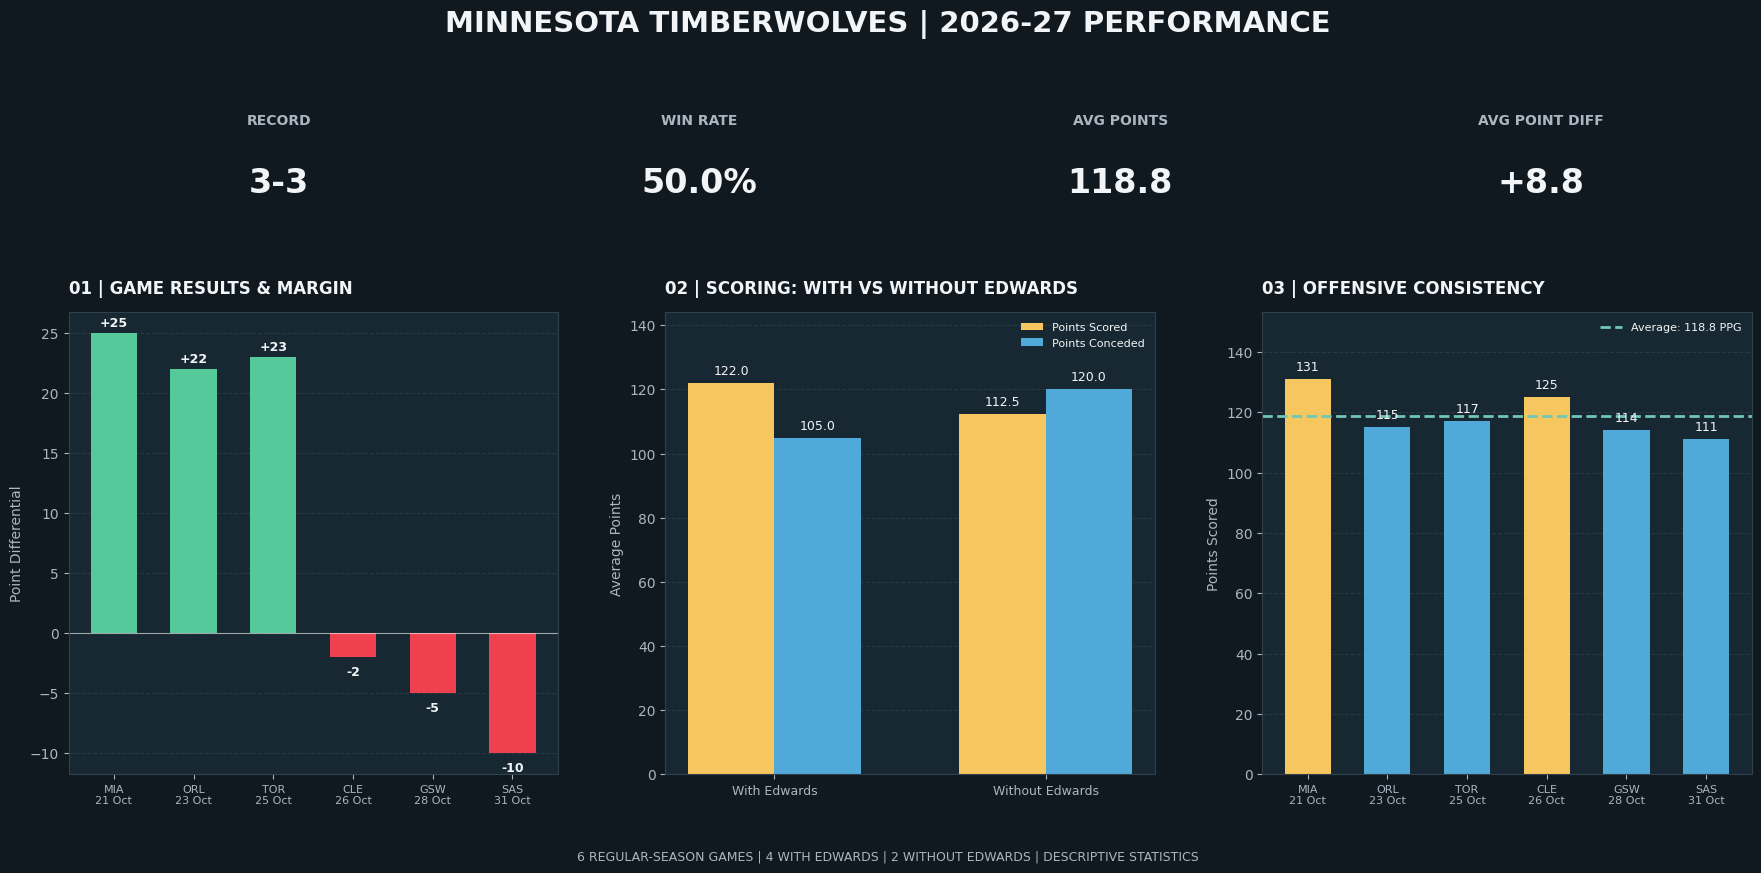

In [ ]:


import matplotlib.pyplot as plt
import numpy as np

# ---------------------------------------------------------
# COLOUR PALETTE
# ---------------------------------------------------------

BG = "#101820"
PANEL = "#172832"
WHITE = "#F2F5F7"
MUTED = "#AAB7C0"
BLUE = "#50A9D8"
RED = "#EF4050"
GOLD = "#F5C75E"
TEAL = "#70C6B7"
GREEN = "#55C99A"
GRID = "#30414B"

plt.rcParams.update({
    "font.family": "DejaVu Sans",
    "text.color": WHITE,
    "axes.labelcolor": MUTED,
    "xtick.color": MUTED,
    "ytick.color": MUTED
})

# ---------------------------------------------------------
# DATA
# ---------------------------------------------------------

data = current_data.sort_values("Date").copy()

overall = calculate_performance(data)

with_edwards_performance = calculate_performance(with_edwards)
without_edwards_performance = calculate_performance(without_edwards)

labels = [
    f"{row['Opponent']}\n{row['Date'].strftime('%d %b')}"
    for _, row in data.iterrows()
]

x = np.arange(len(data))
margins = data["Point_Differential"].values

scored = [
    with_edwards["MIN_PTS"].mean(),
    without_edwards["MIN_PTS"].mean()
]

conceded = [
    with_edwards["OPP_PTS"].mean(),
    without_edwards["OPP_PTS"].mean()
]

# ---------------------------------------------------------
# DASHBOARD LAYOUT
# ---------------------------------------------------------

fig = plt.figure(figsize=(18, 9), facecolor=BG)

gs = fig.add_gridspec(
    2, 3,
    height_ratios=[0.65, 2.5],
    width_ratios=[1, 1, 1],
    hspace=0.35,
    wspace=0.22
)

fig.suptitle(
    "MINNESOTA TIMBERWOLVES | 2026-27 PERFORMANCE",
    fontsize=21,
    fontweight="bold",
    color=WHITE,
    y=0.97
)

# ---------------------------------------------------------
# TOP | SEASON SNAPSHOT
# ---------------------------------------------------------

ax_top = fig.add_subplot(gs[0, :])
ax_top.axis("off")

kpis = [
    ("RECORD", f"{overall['Wins']}-{overall['Losses']}"),
    ("WIN RATE", f"{overall['Win_Percentage']:.1%}"),
    ("AVG POINTS", f"{overall['Average_Points_Scored']:.1f}"),
    ("AVG POINT DIFF", f"{overall['Average_Point_Differential']:+.1f}")
]

for i, (title, value) in enumerate(kpis):
    xpos = (i + 0.5) / 4

    ax_top.text(
        xpos, 0.72, title,
        ha="center",
        fontsize=10,
        fontweight="bold",
        color=MUTED,
        transform=ax_top.transAxes
    )

    ax_top.text(
        xpos, 0.15, value,
        ha="center",
        fontsize=24,
        fontweight="bold",
        color=WHITE,
        transform=ax_top.transAxes
    )

# ---------------------------------------------------------
# 01 | GAME RESULTS & POINT MARGIN
# ---------------------------------------------------------

ax1 = fig.add_subplot(gs[1, 0])
ax1.set_facecolor(PANEL)

bar_colors = [
    GREEN if result == "W" else RED
    for result in data["Result"]
]

bars = ax1.bar(
    x,
    margins,
    color=bar_colors,
    width=0.58
)

ax1.axhline(0, color=WHITE, linewidth=0.8, alpha=0.6)

ax1.set_xticks(x)
ax1.set_xticklabels(labels, fontsize=8)
ax1.set_ylabel("Point Differential")

ax1.set_title(
    "01 | GAME RESULTS & MARGIN",
    loc="left",
    fontsize=12,
    fontweight="bold",
    color=WHITE,
    pad=14
)

ax1.grid(axis="y", color=GRID, linestyle="--", alpha=0.7)
ax1.set_axisbelow(True)

for bar, value in zip(bars, margins):
    ax1.annotate(
        f"{value:+.0f}",
        (bar.get_x() + bar.get_width()/2, value),
        xytext=(0, 5 if value >= 0 else -13),
        textcoords="offset points",
        ha="center",
        color=WHITE,
        fontsize=9,
        fontweight="bold"
    )

# ---------------------------------------------------------
# 02 | SCORING WITH VS WITHOUT EDWARDS
# ---------------------------------------------------------

ax2 = fig.add_subplot(gs[1, 1])
ax2.set_facecolor(PANEL)

categories = ["With Edwards", "Without Edwards"]
x_compare = np.arange(2)
width = 0.32

bars1 = ax2.bar(
    x_compare - width/2,
    scored,
    width,
    color=GOLD,
    label="Points Scored"
)

bars2 = ax2.bar(
    x_compare + width/2,
    conceded,
    width,
    color=BLUE,
    label="Points Conceded"
)

ax2.set_xticks(x_compare)
ax2.set_xticklabels(categories, fontsize=9)
ax2.set_ylabel("Average Points")

ax2.set_title(
    "02 | SCORING: WITH VS WITHOUT EDWARDS",
    loc="left",
    fontsize=12,
    fontweight="bold",
    color=WHITE,
    pad=14
)

ax2.legend(
    facecolor=PANEL,
    edgecolor=GRID,
    labelcolor=WHITE,
    frameon=False,
    fontsize=8
)

ax2.grid(axis="y", color=GRID, linestyle="--", alpha=0.7)
ax2.set_axisbelow(True)

ax2.bar_label(bars1, fmt="%.1f", padding=4, color=WHITE, fontsize=9)
ax2.bar_label(bars2, fmt="%.1f", padding=4, color=WHITE, fontsize=9)

ax2.set_ylim(0, max(max(scored), max(conceded)) + 22)

# ---------------------------------------------------------
# 03 | OFFENSIVE CONSISTENCY
# ---------------------------------------------------------

ax3 = fig.add_subplot(gs[1, 2])
ax3.set_facecolor(PANEL)

average_points = data["MIN_PTS"].mean()

offensive_colors = [
    GOLD if points >= average_points else BLUE
    for points in data["MIN_PTS"]
]

bars3 = ax3.bar(
    x,
    data["MIN_PTS"],
    color=offensive_colors,
    width=0.58
)

ax3.axhline(
    average_points,
    color=TEAL,
    linestyle="--",
    linewidth=2,
    label=f"Average: {average_points:.1f} PPG"
)

ax3.set_xticks(x)
ax3.set_xticklabels(labels, fontsize=8)
ax3.set_ylabel("Points Scored")

ax3.set_title(
    "03 | OFFENSIVE CONSISTENCY",
    loc="left",
    fontsize=12,
    fontweight="bold",
    color=WHITE,
    pad=14
)

ax3.legend(
    facecolor=PANEL,
    edgecolor=GRID,
    labelcolor=WHITE,
    frameon=False,
    fontsize=8
)

ax3.grid(axis="y", color=GRID, linestyle="--", alpha=0.7)
ax3.set_axisbelow(True)

ax3.bar_label(
    bars3,
    fmt="%.0f",
    padding=4,
    color=WHITE,
    fontsize=9
)

ax3.set_ylim(0, data["MIN_PTS"].max() + 22)

# ---------------------------------------------------------
# FINAL FORMATTING
# ---------------------------------------------------------

for ax in [ax1, ax2, ax3]:
    for spine in ax.spines.values():
        spine.set_color(GRID)

fig.text(
    0.5, 0.025,
    "6 REGULAR-SEASON GAMES | 4 WITH EDWARDS | 2 WITHOUT EDWARDS | DESCRIPTIVE STATISTICS",
    ha="center",
    fontsize=9,
    color=MUTED
)

plt.subplots_adjust(
    left=0.045,
    right=0.98,
    top=0.88,
    bottom=0.12
)

plt.show()

plt.rcParams.update(plt.rcParamsDefault)

**LOAD HISTORICAL 2025–26 PLAYER GAME LOGS**

In [ ]:
# CELL 4: LOAD HISTORICAL PLAYER GAME LOGS — 2025-26

import pandas as pd
import requests
from io import BytesIO

DATASET_URL = (
    "https://huggingface.co/datasets/"
    "cbratkovics/nba-game-logs/resolve/main/"
    "game_logs/game_logs_2025-26.parquet"
)

print("Downloading 2025-26 historical player game logs...")

response = requests.get(DATASET_URL, timeout=60)

if response.status_code != 200:
    raise Exception(
        f"Dataset download failed. HTTP Status: {response.status_code}. "
        "We will not proceed with incomplete historical data."
    )

historical_player_logs = pd.read_parquet(BytesIO(response.content))

print("\nDOWNLOAD SUCCESSFUL")
print("=" * 65)

print(f"Total player-game records: {len(historical_player_logs):,}")
print(f"Total columns: {len(historical_player_logs.columns)}")

print("\nAVAILABLE COLUMNS:")
print(historical_player_logs.columns.tolist())

print("\nDATA SAMPLE:")
display(historical_player_logs.head(5))

print("\nDATA TYPES:")
display(
    historical_player_logs.dtypes
    .rename("Data Type")
    .to_frame()
)

print("\nHISTORICAL PLAYER DATA LOADED SUCCESSFULLY")


DOWNLOAD SUCCESSFUL
Total player-game records: 26,648
Total columns: 26

AVAILABLE COLUMNS:
['game_id', 'game_date', 'season', 'player_id', 'player_name', 'team', 'opponent', 'home', 'minutes', 'pts', 'reb', 'ast', 'fgm', 'fga', 'fg3m', 'fg3a', 'ftm', 'fta', 'oreb', 'dreb', 'stl', 'blk', 'tov', 'pf', 'plus_minus', 'source']

DATA SAMPLE:


,game_id,game_date,season,player_id,player_name,team,opponent,home,minutes,pts,reb,ast,fgm,fga,fg3m,fg3a,ftm,fta,oreb,dreb,stl,blk,tov,pf,plus_minus,source
0,0022500001,2025-10-21,2025-26,201142,Kevin Durant,HOU,OKC,False,47.030,23,9,3,9,16,0,4,5,6,0,9,0,0,4,6,0,kaggle_v515
1,0022500001,2025-10-21,2025-26,203500,Steven Adams,HOU,OKC,False,36.300,4,13,3,1,4,0,0,2,2,5,8,0,0,3,4,2,kaggle_v515
2,0022500001,2025-10-21,2025-26,203991,Clint Capela,HOU,OKC,False,7.520,4,0,0,1,1,0,0,2,2,0,0,1,0,1,0,5,kaggle_v515
3,0022500001,2025-10-21,2025-26,1627936,Alex Caruso,OKC,HOU,True,30.110,8,2,3,3,9,2,6,0,0,0,2,2,1,0,2,-15,kaggle_v515
4,0022500001,2025-10-21,2025-26,1628392,Isaiah Hartenstein,OKC,HOU,True,36.510,6,8,5,2,5,0,1,2,2,5,3,2,0,1,6,9,kaggle_v515



DATA TYPES:


,Data Type
game_id,string[python]
game_date,datetime64[us]
season,string[python]
player_id,int64
player_name,string[python]
team,string[python]
opponent,string[python]
home,bool
minutes,float64
pts,int64



HISTORICAL PLAYER DATA LOADED SUCCESSFULLY


**HISTORICAL MINNESOTA GAME & EDWARDS AVAILABILITY AUDIT**

In [ ]:
# CELL 5: HISTORICAL MINNESOTA GAME & EDWARDS AVAILABILITY AUDIT

# ---------------------------------------------------------
# 1. EXTRACT MINNESOTA PLAYER RECORDS
# ---------------------------------------------------------

minnesota_logs = historical_player_logs[
    historical_player_logs["team"].str.upper() == "MIN"
].copy()

minnesota_logs["game_date"] = pd.to_datetime(
    minnesota_logs["game_date"]
)

minnesota_logs = minnesota_logs.sort_values(
    ["game_date", "game_id", "player_name"]
)

print("=" * 75)
print("MINNESOTA TIMBERWOLVES — 2025-26 HISTORICAL DATA AUDIT")
print("=" * 75)

print(f"\nTotal Minnesota player-game records: {len(minnesota_logs):,}")

print(
    "Unique Minnesota games:",
    minnesota_logs["game_id"].nunique()
)

print(
    "Unique Minnesota players:",
    minnesota_logs["player_id"].nunique()
)


# ---------------------------------------------------------
# 2. IDENTIFY ANTHONY EDWARDS' RECORDS
# ---------------------------------------------------------

edwards_logs = minnesota_logs[
    minnesota_logs["player_name"].str.lower()
    == "anthony edwards"
].copy()

edwards_game_ids = set(edwards_logs["game_id"])

print("\nANTHONY EDWARDS DATA COVERAGE")
print("-" * 75)

print(f"Recorded appearances: {len(edwards_logs)}")
print(f"Unique games with records: {len(edwards_game_ids)}")

if len(edwards_logs) > 0:
    print(f"Average points: {edwards_logs['pts'].mean():.2f}")
    print(f"Average minutes: {edwards_logs['minutes'].mean():.2f}")
    print(f"Average assists: {edwards_logs['ast'].mean():.2f}")
    print(f"Average rebounds: {edwards_logs['reb'].mean():.2f}")


# ---------------------------------------------------------
# 3. BUILD MINNESOTA GAME-LEVEL COVERAGE TABLE
# ---------------------------------------------------------

team_game_audit = (
    minnesota_logs
    .groupby(["game_id", "game_date", "opponent", "home"])
    .agg(
        Player_Records=("player_id", "nunique"),
        Total_Points=("pts", "sum"),
        Total_Minutes=("minutes", "sum"),
        Duplicate_Player_Rows=("player_id", "size")
    )
    .reset_index()
)

team_game_audit["Edwards_Record_Found"] = (
    team_game_audit["game_id"].isin(edwards_game_ids)
)

team_game_audit["Edwards_Status_From_Dataset"] = np.where(
    team_game_audit["Edwards_Record_Found"],
    "Record Found",
    "Record Missing"
)

team_game_audit["Location"] = np.where(
    team_game_audit["home"],
    "Home",
    "Away"
)

team_game_audit = team_game_audit.sort_values("game_date")


# ---------------------------------------------------------
# 4. CHECK DATA COMPLETENESS
# ---------------------------------------------------------

team_game_audit["Duplicate_Rows"] = (
    team_game_audit["Duplicate_Player_Rows"]
    - team_game_audit["Player_Records"]
)

print("\nPLAYER RECORD COVERAGE BY GAME")
print("-" * 75)

display(
    team_game_audit[
        [
            "game_date",
            "opponent",
            "Location",
            "Player_Records",
            "Total_Points",
            "Total_Minutes",
            "Edwards_Status_From_Dataset",
            "Duplicate_Rows"
        ]
    ].reset_index(drop=True)
)


# ---------------------------------------------------------
# 5. DATA QUALITY SUMMARY
# ---------------------------------------------------------

print("\nDATA QUALITY SUMMARY")
print("-" * 75)

print(
    "Games with Edwards records:",
    team_game_audit["Edwards_Record_Found"].sum()
)

print(
    "Games without Edwards records:",
    (~team_game_audit["Edwards_Record_Found"]).sum()
)

print(
    "Games with fewer than 8 player records:",
    (team_game_audit["Player_Records"] < 8).sum()
)

print(
    "Games with duplicate player rows:",
    (team_game_audit["Duplicate_Rows"] > 0).sum()
)

print(
    "Games with unusual total minutes (<200 or >300):",
    (
        (team_game_audit["Total_Minutes"] < 200)
        | (team_game_audit["Total_Minutes"] > 300)
    ).sum()
)


# ---------------------------------------------------------
# 6. TOP PLAYER RECORD COUNTS
# ---------------------------------------------------------

print("\nMINNESOTA PLAYER RECORD COUNTS")
print("-" * 75)

player_coverage = (
    minnesota_logs
    .groupby("player_name")
    .agg(
        Recorded_Games=("game_id", "nunique"),
        Average_Minutes=("minutes", "mean"),
        Average_Points=("pts", "mean")
    )
    .sort_values("Recorded_Games", ascending=False)
)

display(player_coverage.head(20))

print("\nAUDIT COMPLETE")
print(
    "IMPORTANT: A missing Edwards record is not yet classified "
    "as a confirmed absence."
)

MINNESOTA TIMBERWOLVES — 2025-26 HISTORICAL DATA AUDIT

Total Minnesota player-game records: 896
Unique Minnesota games: 82
Unique Minnesota players: 21

ANTHONY EDWARDS DATA COVERAGE
---------------------------------------------------------------------------
Recorded appearances: 61
Unique games with records: 61
Average points: 28.80
Average minutes: 34.87
Average assists: 3.70
Average rebounds: 4.95

PLAYER RECORD COVERAGE BY GAME
---------------------------------------------------------------------------


,game_date,opponent,Location,Player_Records,Total_Points,Total_Minutes,Edwards_Status_From_Dataset,Duplicate_Rows
0,2025-10-22,POR,Away,10,118,237.600,Record Found,0
1,2025-10-24,LAL,Away,15,110,236.800,Record Found,0
2,2025-10-26,IND,Home,11,114,238.010,Record Found,0
3,2025-10-27,DEN,Home,12,114,237.600,Record Missing,0
4,2025-10-29,LAL,Home,9,115,238.410,Record Missing,0
5,2025-11-01,CHA,Away,12,122,237.200,Record Missing,0
6,2025-11-03,BKN,Away,12,125,238.000,Record Missing,0
7,2025-11-05,NYK,Away,13,114,238.000,Record Found,0
8,2025-11-07,UTA,Home,14,137,237.200,Record Found,0
9,2025-11-09,SAC,Away,13,144,237.200,Record Found,0



DATA QUALITY SUMMARY
---------------------------------------------------------------------------
Games with Edwards records: 61
Games without Edwards records: 21
Games with fewer than 8 player records: 0
Games with duplicate player rows: 0
Games with unusual total minutes (<200 or >300): 0

MINNESOTA PLAYER RECORD COUNTS
---------------------------------------------------------------------------


,Recorded_Games,Average_Minutes,Average_Points
player_name,,,
Donte DiVincenzo,82,30.235,12.195
Julius Randle,79,32.853,21.101
Naz Reid,77,25.875,13.584
Rudy Gobert,76,31.127,10.908
Jaden McDaniels,73,31.532,14.849
Bones Hyland,71,16.363,8.507
Jaylen Clark,68,12.833,4.044
Anthony Edwards,61,34.865,28.803
Mike Conley,54,18.148,4.537



AUDIT COMPLETE
IMPORTANT: A missing Edwards record is not yet classified as a confirmed absence.


**ISOLATE THE 21 POTENTIAL EDWARDS ABSENCE GAMES**

In [ ]:
# CELL 6: ISOLATE AND AUDIT THE 21 POTENTIAL EDWARDS ABSENCE GAMES

# ---------------------------------------------------------
# 1. IDENTIFY POTENTIAL ABSENCE GAMES
# ---------------------------------------------------------

potential_absence_games = team_game_audit[
    ~team_game_audit["Edwards_Record_Found"]
].copy()

potential_absence_games = potential_absence_games.sort_values(
    "game_date"
).reset_index(drop=True)

print("=" * 75)
print("MINNESOTA — POTENTIAL ANTHONY EDWARDS ABSENCE GAMES")
print("=" * 75)

print(f"\nPotential absence games: {len(potential_absence_games)}")


# ---------------------------------------------------------
# 2. SELECT THE FOUR REDISTRIBUTION PLAYERS
# ---------------------------------------------------------

redistribution_players = [
    "LaMelo Ball",
    "Jaden McDaniels",
    "Jonathan Kuminga",
    "Ayo Dosunmu"
]

absence_game_ids = set(potential_absence_games["game_id"])

absence_player_logs = minnesota_logs[
    minnesota_logs["game_id"].isin(absence_game_ids)
].copy()

selected_player_logs = absence_player_logs[
    absence_player_logs["player_name"].isin(redistribution_players)
].copy()


# ---------------------------------------------------------
# 3. PLAYER PRODUCTION IN POTENTIAL ABSENCE GAMES
# ---------------------------------------------------------

player_absence_summary = (
    selected_player_logs
    .groupby("player_name")
    .agg(
        Games_Recorded=("game_id", "nunique"),
        Average_Minutes=("minutes", "mean"),
        Average_Points=("pts", "mean"),
        Average_Rebounds=("reb", "mean"),
        Average_Assists=("ast", "mean"),
        Average_FGA=("fga", "mean"),
        Average_FG3A=("fg3a", "mean"),
        Average_Turnovers=("tov", "mean")
    )
    .reindex(redistribution_players)
)

print("\nSELECTED PLAYERS — PRODUCTION IN POTENTIAL ABSENCE GAMES")
print("-" * 75)

display(player_absence_summary.round(2))


# ---------------------------------------------------------
# 4. GAME-BY-GAME PLAYER PRODUCTION
# ---------------------------------------------------------

game_player_production = (
    selected_player_logs
    .pivot_table(
        index=["game_date", "opponent"],
        columns="player_name",
        values="pts",
        aggfunc="sum"
    )
    .reset_index()
)

print("\nGAME-BY-GAME SCORING — SELECTED PLAYERS")
print("-" * 75)

display(game_player_production)


# ---------------------------------------------------------
# 5. DATA COVERAGE OF EACH POTENTIAL ABSENCE GAME
# ---------------------------------------------------------

absence_coverage = potential_absence_games[
    [
        "game_date",
        "opponent",
        "Location",
        "Player_Records",
        "Total_Points",
        "Total_Minutes",
        "Duplicate_Rows"
    ]
].copy()

absence_coverage["Total_Minutes"] = (
    absence_coverage["Total_Minutes"].round(1)
)

print("\nPOTENTIAL ABSENCE GAME DATA COVERAGE")
print("-" * 75)

display(absence_coverage)


# ---------------------------------------------------------
# 6. VALIDATION SUMMARY
# ---------------------------------------------------------

print("\nVALIDATION SUMMARY")
print("-" * 75)

print(f"Total potential absence games: {len(absence_game_ids)}")

print(
    "Selected-player records found:",
    len(selected_player_logs)
)

print(
    "Potential absence games with at least 8 player records:",
    (potential_absence_games["Player_Records"] >= 8).sum()
)

print(
    "Potential absence games with at least 240 recorded minutes:",
    (potential_absence_games["Total_Minutes"] >= 240).sum()
)

print(
    "Potential absence games with fewer than 240 recorded minutes:",
    (potential_absence_games["Total_Minutes"] < 240).sum()
)

print("\nIMPORTANT:")
print(
    "These are candidate absence games based on missing Edwards records. "
    "They are not yet independently verified."
)

MINNESOTA — POTENTIAL ANTHONY EDWARDS ABSENCE GAMES

Potential absence games: 21

SELECTED PLAYERS — PRODUCTION IN POTENTIAL ABSENCE GAMES
---------------------------------------------------------------------------


,Games_Recorded,Average_Minutes,Average_Points,Average_Rebounds,Average_Assists,Average_FGA,Average_FG3A,Average_Turnovers
player_name,,,,,,,,
LaMelo Ball,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Jaden McDaniels,16.000,33.190,18.690,4.620,3.190,13.880,4.190,1.690
Jonathan Kuminga,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Ayo Dosunmu,7.000,32.940,18.710,6.570,4.140,14.140,4.710,2.430



GAME-BY-GAME SCORING — SELECTED PLAYERS
---------------------------------------------------------------------------


player_name,game_date,opponent,Ayo Dosunmu,Jaden McDaniels
0,2025-10-27,DEN,NaN,25.000
1,2025-10-29,LAL,NaN,30.000
2,2025-11-01,CHA,NaN,14.000
3,2025-11-03,BKN,NaN,22.000
4,2025-12-12,GSW,NaN,17.000
5,2025-12-14,SAC,NaN,21.000
6,2025-12-17,MEM,NaN,13.000
7,2026-01-13,MIL,NaN,17.000
8,2026-01-16,HOU,NaN,15.000
9,2026-01-26,GSW,NaN,14.000



POTENTIAL ABSENCE GAME DATA COVERAGE
---------------------------------------------------------------------------


,game_date,opponent,Location,Player_Records,Total_Points,Total_Minutes,Duplicate_Rows
0,2025-10-27,DEN,Home,12,114,237.600,0
1,2025-10-29,LAL,Home,9,115,238.400,0
2,2025-11-01,CHA,Away,12,122,237.200,0
3,2025-11-03,BKN,Away,12,125,238.000,0
4,2025-12-12,GSW,Away,9,127,238.400,0
5,2025-12-14,SAC,Home,9,117,238.000,0
6,2025-12-17,MEM,Home,9,110,238.400,0
7,2026-01-13,MIL,Away,12,139,238.000,0
8,2026-01-16,HOU,Away,9,105,238.400,0
9,2026-01-26,GSW,Home,12,108,237.600,0



VALIDATION SUMMARY
---------------------------------------------------------------------------
Total potential absence games: 21
Selected-player records found: 23
Potential absence games with at least 8 player records: 21
Potential absence games with at least 240 recorded minutes: 1
Potential absence games with fewer than 240 recorded minutes: 20

IMPORTANT:
These are candidate absence games based on missing Edwards records. They are not yet independently verified.


**RECONSTRUCT HISTORICAL TEAM SCORES AND RESULTS**

In [ ]:
# CELL 7: RECONSTRUCT MINNESOTA'S 2025-26 GAME RESULTS

# ---------------------------------------------------------
# 1. RECONSTRUCT TEAM SCORES FROM PLAYER RECORDS
# ---------------------------------------------------------

team_scores = (
    historical_player_logs
    .groupby(["game_id", "team"], as_index=False)
    .agg(
        Team_Points=("pts", "sum"),
        Player_Records=("player_id", "nunique"),
        Total_Player_Minutes=("minutes", "sum")
    )
)

# ---------------------------------------------------------
# 2. GET MINNESOTA'S GAME AND OPPONENT INFORMATION
# ---------------------------------------------------------

min_games = minnesota_logs[
    [
        "game_id",
        "game_date",
        "team",
        "opponent",
        "home"
    ]
].drop_duplicates("game_id").copy()

min_games = min_games.merge(
    team_scores[["game_id", "team", "Team_Points"]],
    on=["game_id", "team"],
    how="left"
)

# ---------------------------------------------------------
# 3. MATCH OPPONENT SCORES
# ---------------------------------------------------------

opponent_scores = team_scores.rename(
    columns={
        "team": "opponent",
        "Team_Points": "Opponent_Points",
        "Player_Records": "Opponent_Player_Records",
        "Total_Player_Minutes": "Opponent_Total_Minutes"
    }
)

min_games = min_games.merge(
    opponent_scores[
        [
            "game_id",
            "opponent",
            "Opponent_Points",
            "Opponent_Player_Records",
            "Opponent_Total_Minutes"
        ]
    ],
    on=["game_id", "opponent"],
    how="left"
)

# ---------------------------------------------------------
# 4. CALCULATE RESULTS
# ---------------------------------------------------------

min_games["Point_Differential"] = (
    min_games["Team_Points"] - min_games["Opponent_Points"]
)

min_games["Result"] = np.select(
    [
        min_games["Point_Differential"] > 0,
        min_games["Point_Differential"] < 0
    ],
    ["W", "L"],
    default="T"
)

min_games["Location"] = np.where(
    min_games["home"],
    "Home",
    "Away"
)

# ---------------------------------------------------------
# 5. MERGE EDWARDS RECORD STATUS
# ---------------------------------------------------------

min_games["Edwards_Record_Found"] = (
    min_games["game_id"].isin(edwards_game_ids)
)

min_games["Edwards_Dataset_Status"] = np.where(
    min_games["Edwards_Record_Found"],
    "Record Found",
    "Record Missing"
)

# ---------------------------------------------------------
# 6. ISOLATE THE 21 CANDIDATE ABSENCE GAMES
# ---------------------------------------------------------

historical_absence_results = (
    min_games[
        ~min_games["Edwards_Record_Found"]
    ]
    .sort_values("game_date")
    .reset_index(drop=True)
)

# ---------------------------------------------------------
# 7. DISPLAY ALL 21 RESULTS
# ---------------------------------------------------------

print("=" * 75)
print("MINNESOTA — 2025-26 CANDIDATE ABSENCE GAME RESULTS")
print("=" * 75)

display(
    historical_absence_results[
        [
            "game_date",
            "opponent",
            "Location",
            "Team_Points",
            "Opponent_Points",
            "Point_Differential",
            "Result",
            "Opponent_Player_Records"
        ]
    ]
)

# ---------------------------------------------------------
# 8. CALCULATE HISTORICAL RECORD
# ---------------------------------------------------------

valid_results = historical_absence_results.dropna(
    subset=["Team_Points", "Opponent_Points"]
)

wins = (valid_results["Result"] == "W").sum()
losses = (valid_results["Result"] == "L").sum()
ties = (valid_results["Result"] == "T").sum()

print("\nHISTORICAL CANDIDATE ABSENCE RECORD")
print("-" * 75)

print(f"Games identified: {len(historical_absence_results)}")
print(f"Games with reconstructed scores: {len(valid_results)}")
print(f"Wins: {wins}")
print(f"Losses: {losses}")
print(f"Ties: {ties}")

if len(valid_results) > 0:
    print(f"Win percentage: {wins / len(valid_results):.2%}")
    print(
        "Average points scored:",
        round(valid_results["Team_Points"].mean(), 2)
    )
    print(
        "Average points conceded:",
        round(valid_results["Opponent_Points"].mean(), 2)
    )
    print(
        "Average point differential:",
        round(valid_results["Point_Differential"].mean(), 2)
    )

# ---------------------------------------------------------
# 9. DATA COMPLETENESS CHECK
# ---------------------------------------------------------

print("\nDATA COMPLETENESS")
print("-" * 75)

print(
    "Missing Minnesota scores:",
    historical_absence_results["Team_Points"].isna().sum()
)

print(
    "Missing opponent scores:",
    historical_absence_results["Opponent_Points"].isna().sum()
)

print(
    "Missing opponent team records:",
    historical_absence_results["Opponent_Player_Records"].isna().sum()
)

print("\nSCORE RECONSTRUCTION COMPLETE")

MINNESOTA — 2025-26 CANDIDATE ABSENCE GAME RESULTS


,game_date,opponent,Location,Team_Points,Opponent_Points,Point_Differential,Result,Opponent_Player_Records
0,2025-10-27,DEN,Home,114,127,-13,L,15
1,2025-10-29,LAL,Home,115,116,-1,L,9
2,2025-11-01,CHA,Away,122,105,17,W,10
3,2025-11-03,BKN,Away,125,109,16,W,13
4,2025-12-12,GSW,Away,127,120,7,W,11
5,2025-12-14,SAC,Home,117,103,14,W,9
6,2025-12-17,MEM,Home,110,116,-6,L,10
7,2026-01-13,MIL,Away,139,106,33,W,14
8,2026-01-16,HOU,Away,105,110,-5,L,10
9,2026-01-26,GSW,Home,108,83,25,W,10



HISTORICAL CANDIDATE ABSENCE RECORD
---------------------------------------------------------------------------
Games identified: 21
Games with reconstructed scores: 21
Wins: 12
Losses: 9
Ties: 0
Win percentage: 57.14%
Average points scored: 116.19
Average points conceded: 110.67
Average point differential: 5.52

DATA COMPLETENESS
---------------------------------------------------------------------------
Missing Minnesota scores: 0
Missing opponent scores: 0
Missing opponent team records: 0

SCORE RECONSTRUCTION COMPLETE


**2025–26 NBA TEAM STRENGTH MODEL**

In [ ]:
# CELL 8: BUILD 2025-26 NBA TEAM STRENGTH RATINGS

# ---------------------------------------------------------
# 1. RECONSTRUCT ALL TEAM SCORES
# ---------------------------------------------------------

all_team_scores = (
    historical_player_logs
    .groupby(["game_id", "game_date", "team", "opponent", "home"])
    .agg(
        Points_Scored=("pts", "sum"),
        Player_Records=("player_id", "nunique")
    )
    .reset_index()
)

# ---------------------------------------------------------
# 2. MATCH OPPONENT SCORES
# ---------------------------------------------------------

opponent_score_lookup = all_team_scores[
    ["game_id", "team", "Points_Scored"]
].rename(
    columns={
        "team": "opponent",
        "Points_Scored": "Points_Conceded"
    }
)

all_team_scores = all_team_scores.merge(
    opponent_score_lookup,
    on=["game_id", "opponent"],
    how="left",
    validate="one_to_one"
)

all_team_scores["Point_Differential"] = (
    all_team_scores["Points_Scored"]
    - all_team_scores["Points_Conceded"]
)

all_team_scores["Location"] = np.where(
    all_team_scores["home"], "Home", "Away"
)

# ---------------------------------------------------------
# 3. VALIDATE GAME DATA
# ---------------------------------------------------------

print("=" * 75)
print("2025-26 NBA TEAM STRENGTH ANALYSIS")
print("=" * 75)

print(f"\nTeam-game records: {len(all_team_scores)}")
print(f"Unique teams: {all_team_scores['team'].nunique()}")
print(f"Unique games: {all_team_scores['game_id'].nunique()}")

print(
    "Missing opponent scores:",
    all_team_scores["Points_Conceded"].isna().sum()
)

if all_team_scores["Points_Conceded"].isna().any():
    raise ValueError(
        "Some opponent scores could not be reconstructed. "
        "Do not proceed with incomplete team ratings."
    )

# ---------------------------------------------------------
# 4. CALCULATE BASIC TEAM PERFORMANCE
# ---------------------------------------------------------

team_strength = (
    all_team_scores
    .groupby("team")
    .agg(
        Games=("game_id", "nunique"),
        Average_Points_Scored=("Points_Scored", "mean"),
        Average_Points_Conceded=("Points_Conceded", "mean"),
        Average_Point_Differential=("Point_Differential", "mean"),
        Total_Point_Differential=("Point_Differential", "sum")
    )
    .reset_index()
)

# ---------------------------------------------------------
# 5. CALCULATE OPPONENT-ADJUSTED RATING
# ---------------------------------------------------------

# SRS-style rating:
# Team rating = average point differential
#              + average opponent rating

team_ratings = {
    team: 0.0
    for team in team_strength["team"]
}

for iteration in range(1000):

    updated_ratings = {}

    for team in team_strength["team"]:

        team_games = all_team_scores[
            all_team_scores["team"] == team
        ]

        opponent_rating = np.mean([
            team_ratings[opp]
            for opp in team_games["opponent"]
        ])

        average_margin = team_games["Point_Differential"].mean()

        updated_ratings[team] = (
            average_margin + opponent_rating
        )

    # Center ratings around zero
    rating_mean = np.mean(list(updated_ratings.values()))

    updated_ratings = {
        team: rating - rating_mean
        for team, rating in updated_ratings.items()
    }

    max_change = max(
        abs(updated_ratings[t] - team_ratings[t])
        for t in team_ratings
    )

    team_ratings = updated_ratings

    if max_change < 1e-10:
        break

team_strength["SRS_Style_Rating"] = (
    team_strength["team"].map(team_ratings)
)

team_strength["Rank"] = (
    team_strength["SRS_Style_Rating"]
    .rank(ascending=False, method="min")
    .astype(int)
)

team_strength = team_strength.sort_values(
    "SRS_Style_Rating",
    ascending=False
).reset_index(drop=True)

# ---------------------------------------------------------
# 6. HOME AND AWAY PERFORMANCE
# ---------------------------------------------------------

location_performance = (
    all_team_scores
    .groupby(["team", "Location"])
    .agg(
        Games=("game_id", "nunique"),
        Average_Margin=("Point_Differential", "mean")
    )
    .reset_index()
)

location_pivot = location_performance.pivot(
    index="team",
    columns="Location",
    values="Average_Margin"
).reset_index()

team_strength = team_strength.merge(
    location_pivot,
    on="team",
    how="left"
)

# ---------------------------------------------------------
# 7. DISPLAY LEAGUE RATINGS
# ---------------------------------------------------------

print("\n2025-26 LEAGUE TEAM RATINGS")
print("-" * 75)

display(
    team_strength[
        [
            "Rank",
            "team",
            "Games",
            "Average_Points_Scored",
            "Average_Points_Conceded",
            "Average_Point_Differential",
            "SRS_Style_Rating",
            "Home",
            "Away"
        ]
    ].round(2)
)

# ---------------------------------------------------------
# 8. MINNESOTA SPECIFIC ANALYSIS
# ---------------------------------------------------------

minnesota_rating = team_strength[
    team_strength["team"] == "MIN"
].iloc[0]

print("\nMINNESOTA TIMBERWOLVES — TEAM STRENGTH")
print("-" * 75)

print(f"League rank: {minnesota_rating['Rank']}")
print(f"Games: {minnesota_rating['Games']}")
print(
    f"Average scoring: "
    f"{minnesota_rating['Average_Points_Scored']:.2f}"
)
print(
    f"Average points conceded: "
    f"{minnesota_rating['Average_Points_Conceded']:.2f}"
)
print(
    f"Average point differential: "
    f"{minnesota_rating['Average_Point_Differential']:+.2f}"
)
print(
    f"Opponent-adjusted rating: "
    f"{minnesota_rating['SRS_Style_Rating']:+.2f}"
)

print("\nTEAM STRENGTH MODEL CREATED SUCCESSFULLY")

2025-26 NBA TEAM STRENGTH ANALYSIS

Team-game records: 2460
Unique teams: 30
Unique games: 1230
Missing opponent scores: 0

2025-26 LEAGUE TEAM RATINGS
---------------------------------------------------------------------------


,Rank,team,Games,Average_Points_Scored,Average_Points_Conceded,Average_Point_Differential,SRS_Style_Rating,Home,Away
0,1,OKC,82,119.020,107.880,11.150,11.040,11.480,10.800
1,2,SAN,82,119.830,111.520,8.300,8.280,8.620,8.000
2,3,DET,82,117.770,109.610,8.160,7.530,10.490,5.830
3,4,BOS,82,114.850,107.160,7.700,7.370,7.830,7.560
4,5,NYK,82,116.450,110.120,6.330,6.050,10.020,2.810
5,6,DEN,82,122.070,116.930,5.150,4.970,5.590,4.710
6,7,HOU,82,115.230,110.010,5.220,4.870,7.490,2.950
7,8,CHA,82,116.010,111.180,4.830,4.480,3.900,5.760
8,9,CLE,82,119.520,115.410,4.110,3.770,4.540,3.680
9,10,MIN,82,118.000,114.650,3.350,3.070,3.680,3.020



MINNESOTA TIMBERWOLVES — TEAM STRENGTH
---------------------------------------------------------------------------
League rank: 10
Games: 82
Average scoring: 118.00
Average points conceded: 114.65
Average point differential: +3.35
Opponent-adjusted rating: +3.07

TEAM STRENGTH MODEL CREATED SUCCESSFULLY


**Calculate Home-Court Advantage and Schedule Strength**

In [ ]:
# CELL 9: HOME-COURT ADVANTAGE & SCHEDULE OPPONENT STRENGTH

# --------------------------------------------------
# 1. HISTORICAL HOME-COURT ADVANTAGE
# --------------------------------------------------

game_level_scores = (
    all_team_scores
    .pivot_table(
        index="game_id",
        columns="home",
        values="Points_Scored",
        aggfunc="first"
    )
    .dropna()
)

game_level_scores.columns = ["Away_Points", "Home_Points"]

game_level_scores["Home_Margin"] = (
    game_level_scores["Home_Points"] -
    game_level_scores["Away_Points"]
)

HOME_COURT_ADVANTAGE = game_level_scores["Home_Margin"].mean()

print("=" * 75)
print("HOME-COURT ADVANTAGE ANALYSIS")
print("=" * 75)

print(f"Historical games analysed: {len(game_level_scores):,}")
print(f"Average home-court advantage: {HOME_COURT_ADVANTAGE:+.2f} points")
print(f"Median home-court advantage: {game_level_scores['Home_Margin'].median():+.2f} points")

# --------------------------------------------------
# 2. NORMALIZE TEAM ABBREVIATIONS
# --------------------------------------------------

TEAM_ALIASES = {
    "SAN": "SAS"
}

team_strength["team"] = team_strength["team"].replace(TEAM_ALIASES)

team_ratings = dict(
    zip(
        team_strength["team"],
        team_strength["SRS_Style_Rating"]
    )
)

# --------------------------------------------------
# 3. MAP OPPONENT STRENGTH TO THE SCHEDULE
# --------------------------------------------------

schedule_analysis = schedule.copy()

schedule_analysis["Opponent"] = (
    schedule_analysis["Opponent"].replace(TEAM_ALIASES)
)

schedule_analysis["Opponent_SRS"] = (
    schedule_analysis["Opponent"].map(team_ratings)
)

schedule_analysis["Minnesota_Home"] = (
    schedule_analysis["Location"].str.lower() == "home"
)

schedule_analysis["Home_Court_Adjustment"] = np.where(
    schedule_analysis["Minnesota_Home"],
    HOME_COURT_ADVANTAGE,
    -HOME_COURT_ADVANTAGE
)

schedule_analysis["Opponent_Rank"] = (
    schedule_analysis["Opponent"].map(
        team_strength.set_index("team")["Rank"]
    )
)

# --------------------------------------------------
# 4. VALIDATE MATCHING
# --------------------------------------------------

missing_opponents = schedule_analysis[
    schedule_analysis["Opponent_SRS"].isna()
]

print("\n" + "=" * 75)
print("SCHEDULE MATCHING VALIDATION")
print("=" * 75)

print(f"Scheduled games: {len(schedule_analysis)}")
print(f"Opponents matched: {schedule_analysis['Opponent_SRS'].notna().sum()}")
print(f"Unmatched opponents: {len(missing_opponents)}")

if len(missing_opponents) > 0:
    display(missing_opponents[["Date", "Opponent", "Location"]])
    raise ValueError("Unmatched opponents detected.")

# --------------------------------------------------
# 5. DISPLAY SCHEDULE STRENGTH
# --------------------------------------------------

schedule_strength_view = schedule_analysis[
    [
        "Game_Number",
        "Date",
        "Opponent",
        "Location",
        "Opponent_Rank",
        "Opponent_SRS",
        "Home_Court_Adjustment"
    ]
].copy()

schedule_strength_view["Opponent_SRS"] = (
    schedule_strength_view["Opponent_SRS"].round(2)
)

schedule_strength_view["Home_Court_Adjustment"] = (
    schedule_strength_view["Home_Court_Adjustment"].round(2)
)

print("\n" + "=" * 75)
print("MINNESOTA SCHEDULE — OPPONENT STRENGTH")
print("=" * 75)

display(schedule_strength_view)

print(
    "\nAverage opponent rating:",
    round(schedule_analysis["Opponent_SRS"].mean(), 2)
)

print("\nSCHEDULE STRENGTH ANALYSIS COMPLETED")

HOME-COURT ADVANTAGE ANALYSIS
Historical games analysed: 1,230
Average home-court advantage: +1.74 points
Median home-court advantage: +3.00 points

SCHEDULE MATCHING VALIDATION
Scheduled games: 18
Opponents matched: 18
Unmatched opponents: 0

MINNESOTA SCHEDULE — OPPONENT STRENGTH


,Game_Number,Date,Opponent,Location,Opponent_Rank,Opponent_SRS,Home_Court_Adjustment
0,1,2026-10-31,SAS,Away,2,8.280,-1.740
1,2,2026-11-02,MIL,Home,25,-6.120,1.740
2,3,2026-11-04,HOU,Away,7,4.870,-1.740
3,4,2026-11-08,UTA,Home,27,-8.040,1.740
4,5,2026-11-12,DAL,Home,23,-5.330,1.740
5,6,2026-11-14,CHI,Home,22,-5.090,1.740
6,7,2026-11-16,POR,Home,19,-0.280,1.740
7,8,2026-11-17,POR,Home,19,-0.280,1.740
8,9,2026-11-19,NYK,Home,5,6.050,1.740
9,10,2026-11-21,MEM,Home,24,-5.830,1.740



Average opponent rating: -1.75

SCHEDULE STRENGTH ANALYSIS COMPLETED


**Inspect the No-Edwards Baseline Data**

In [ ]:
# CELL 10: INSPECT HISTORICAL AND CURRENT NO-EDWARDS RESULTS

print("=" * 75)
print("HISTORICAL NO-EDWARDS DATA — 2025-26")
print("=" * 75)

print("Rows:", len(historical_absence_results))
print("Columns:", historical_absence_results.columns.tolist())

display(historical_absence_results.head(5))

print("\nHistorical result summary:")
display(
    historical_absence_results[
        "Result"
    ].value_counts()
    if "Result" in historical_absence_results.columns
    else historical_absence_results.describe(include="all")
)

print("\n" + "=" * 75)
print("CURRENT SEASON RESULTS — 2026-27")
print("=" * 75)

print("Available variables containing current-season data:")

for variable_name in [
    "current_season_results",
    "current_results",
    "current_season_games",
    "current_games"
]:
    if variable_name in globals():
        obj = globals()[variable_name]
        print(f"\n{variable_name}:")
        if isinstance(obj, pd.DataFrame):
            print("Rows:", len(obj))
            print("Columns:", obj.columns.tolist())
            display(obj)
        else:
            print(obj)

print("\nInspection completed.")

HISTORICAL NO-EDWARDS DATA — 2025-26
Rows: 21
Columns: ['game_id', 'game_date', 'team', 'opponent', 'home', 'Team_Points', 'Opponent_Points', 'Opponent_Player_Records', 'Opponent_Total_Minutes', 'Point_Differential', 'Result', 'Location', 'Edwards_Record_Found', 'Edwards_Dataset_Status']


,game_id,game_date,team,opponent,home,Team_Points,Opponent_Points,Opponent_Player_Records,Opponent_Total_Minutes,Point_Differential,Result,Location,Edwards_Record_Found,Edwards_Dataset_Status
0,0022500008,2025-10-27,MIN,DEN,True,114,127,15,237.210,-13,L,Home,False,Record Missing
1,0022500136,2025-10-29,MIN,LAL,True,115,116,9,238.400,-1,L,Home,False,Record Missing
2,0022500143,2025-11-01,MIN,CHA,False,122,105,10,237.600,17,W,Away,False,Record Missing
3,0022500156,2025-11-03,MIN,BKN,False,125,109,13,236.800,16,W,Away,False,Record Missing
4,0022501215,2025-12-12,MIN,GSW,False,127,120,11,237.600,7,W,Away,False,Record Missing



Historical result summary:


,count
Result,
W,12
L,9



CURRENT SEASON RESULTS — 2026-27
Available variables containing current-season data:

Inspection completed.


**Build and Validate the Current-Season Dataset**

In [ ]:
# CELL 11: RECONSTRUCT CURRENT-SEASON RESULTS

current_season_results = pd.DataFrame([
    {
        "Date": "2026-10-21",
        "Opponent": "MIA",
        "Location": "Away",
        "Team_Points": 131,
        "Opponent_Points": 106,
        "Edwards_Status": "Played"
    },
    {
        "Date": "2026-10-23",
        "Opponent": "ORL",
        "Location": "Away",
        "Team_Points": 115,
        "Opponent_Points": 93,
        "Edwards_Status": "Played"
    },
    {
        "Date": "2026-10-25",
        "Opponent": "TOR",
        "Location": "Home",
        "Team_Points": 117,
        "Opponent_Points": 94,
        "Edwards_Status": "Played"
    },
    {
        "Date": "2026-10-26",
        "Opponent": "CLE",
        "Location": "Away",
        "Team_Points": 125,
        "Opponent_Points": 127,
        "Edwards_Status": "Played"
    },
    {
        "Date": "2026-10-28",
        "Opponent": "GSW",
        "Location": "Home",
        "Team_Points": 114,
        "Opponent_Points": 119,
        "Edwards_Status": "Absent"
    },
    {
        "Date": "2026-10-31",
        "Opponent": "SAS",
        "Location": "Away",
        "Team_Points": 111,
        "Opponent_Points": 121,
        "Edwards_Status": "Absent"
    }
])

current_season_results["Date"] = pd.to_datetime(
    current_season_results["Date"]
)

current_season_results["Point_Differential"] = (
    current_season_results["Team_Points"] -
    current_season_results["Opponent_Points"]
)

current_season_results["Result"] = np.where(
    current_season_results["Point_Differential"] > 0,
    "W",
    "L"
)

# --------------------------------------------------
# SEASON SUMMARY
# --------------------------------------------------

def summarize_results(df, label):
    wins = (df["Result"] == "W").sum()
    losses = (df["Result"] == "L").sum()
    games = len(df)

    return {
        "Category": label,
        "Games": games,
        "Wins": wins,
        "Losses": losses,
        "Win_Rate": wins / games if games else np.nan,
        "Points_Scored": df["Team_Points"].mean(),
        "Points_Conceded": df["Opponent_Points"].mean(),
        "Average_Margin": df["Point_Differential"].mean()
    }

current_summary = pd.DataFrame([
    summarize_results(current_season_results, "Overall"),
    summarize_results(
        current_season_results[
            current_season_results["Edwards_Status"] == "Played"
        ],
        "Edwards Played"
    ),
    summarize_results(
        current_season_results[
            current_season_results["Edwards_Status"] == "Absent"
        ],
        "Edwards Absent"
    )
])

print("=" * 75)
print("2026-27 CURRENT SEASON RESULTS")
print("=" * 75)

display(current_season_results)

print("\nCURRENT SEASON SUMMARY")
display(current_summary.round(3))

# --------------------------------------------------
# HISTORICAL ABSENCE SUMMARY
# --------------------------------------------------

historical_summary = summarize_results(
    historical_absence_results,
    "2025-26 Candidate Absence Games"
)

print("\nHISTORICAL CANDIDATE ABSENCE SUMMARY")
display(pd.DataFrame([historical_summary]).round(3))

# --------------------------------------------------
# VALIDATION
# --------------------------------------------------

assert len(current_season_results) == 6
assert len(current_season_results[
    current_season_results["Edwards_Status"] == "Absent"
]) == 2

assert (
    current_season_results["Point_Differential"].sum()
    ==
    (
        current_season_results["Team_Points"].sum()
        -
        current_season_results["Opponent_Points"].sum()
    )
)

print("\nVALIDATION PASSED")

2026-27 CURRENT SEASON RESULTS


,Date,Opponent,Location,Team_Points,Opponent_Points,Edwards_Status,Point_Differential,Result
0,2026-10-21,MIA,Away,131,106,Played,25,W
1,2026-10-23,ORL,Away,115,93,Played,22,W
2,2026-10-25,TOR,Home,117,94,Played,23,W
3,2026-10-26,CLE,Away,125,127,Played,-2,L
4,2026-10-28,GSW,Home,114,119,Absent,-5,L
5,2026-10-31,SAS,Away,111,121,Absent,-10,L



CURRENT SEASON SUMMARY


,Category,Games,Wins,Losses,Win_Rate,Points_Scored,Points_Conceded,Average_Margin
0,Overall,6,3,3,0.500,118.833,110.000,8.833
1,Edwards Played,4,3,1,0.750,122.000,105.000,17.000
2,Edwards Absent,2,0,2,0.000,112.500,120.000,-7.500



HISTORICAL CANDIDATE ABSENCE SUMMARY


,Category,Games,Wins,Losses,Win_Rate,Points_Scored,Points_Conceded,Average_Margin
0,2025-26 Candidate Absence Games,21,12,9,0.571,116.190,110.667,5.524



VALIDATION PASSED


**Calculate the Opponent-Adjusted No-Edwards Rating**

In [ ]:
# CELL 12: OPPONENT-ADJUSTED NO-EDWARDS TEAM RATING

# --------------------------------------------------
# 1. PREPARE HISTORICAL CANDIDATE ABSENCE GAMES
# --------------------------------------------------

historical_no_edwards = historical_absence_results.copy()

historical_no_edwards["Opponent"] = (
    historical_no_edwards["opponent"].replace(TEAM_ALIASES)
)

historical_no_edwards["Location"] = (
    historical_no_edwards["Location"].str.title()
)

historical_no_edwards["Opponent_SRS"] = (
    historical_no_edwards["Opponent"].map(team_ratings)
)

historical_no_edwards["Home_Court_Adjustment"] = np.where(
    historical_no_edwards["Location"] == "Home",
    HOME_COURT_ADVANTAGE,
    -HOME_COURT_ADVANTAGE
)

# --------------------------------------------------
# 2. PREPARE CURRENT-SEASON ABSENCE GAMES
# --------------------------------------------------

current_no_edwards = current_season_results[
    current_season_results["Edwards_Status"] == "Absent"
].copy()

current_no_edwards["Opponent"] = (
    current_no_edwards["Opponent"].replace(TEAM_ALIASES)
)

current_no_edwards["Opponent_SRS"] = (
    current_no_edwards["Opponent"].map(team_ratings)
)

current_no_edwards["Home_Court_Adjustment"] = np.where(
    current_no_edwards["Location"] == "Home",
    HOME_COURT_ADVANTAGE,
    -HOME_COURT_ADVANTAGE
)

# --------------------------------------------------
# 3. VALIDATE OPPONENT RATINGS
# --------------------------------------------------

if historical_no_edwards["Opponent_SRS"].isna().any():
    raise ValueError("Missing historical opponent ratings.")

if current_no_edwards["Opponent_SRS"].isna().any():
    raise ValueError("Missing current opponent ratings.")

# --------------------------------------------------
# 4. INFER MINNESOTA'S NO-EDWARDS TEAM RATING
# --------------------------------------------------
# Formula:
# Team Rating = Actual Margin + Opponent SRS - Home Adjustment

historical_no_edwards["Inferred_Team_Rating"] = (
    historical_no_edwards["Point_Differential"]
    + historical_no_edwards["Opponent_SRS"]
    - historical_no_edwards["Home_Court_Adjustment"]
)

current_no_edwards["Inferred_Team_Rating"] = (
    current_no_edwards["Point_Differential"]
    + current_no_edwards["Opponent_SRS"]
    - current_no_edwards["Home_Court_Adjustment"]
)

# --------------------------------------------------
# 5. CALCULATE SEASON-LEVEL RATINGS
# --------------------------------------------------

historical_no_edwards_rating = (
    historical_no_edwards["Inferred_Team_Rating"].mean()
)

current_no_edwards_rating = (
    current_no_edwards["Inferred_Team_Rating"].mean()
)

# Explicitly configured prior weights
HISTORICAL_WEIGHT = 0.80
CURRENT_WEIGHT = 0.20

BASE_NO_EDWARDS_RATING = (
    historical_no_edwards_rating * HISTORICAL_WEIGHT
    +
    current_no_edwards_rating * CURRENT_WEIGHT
)

# --------------------------------------------------
# 6. BUILD COMPARISON TABLE
# --------------------------------------------------

rating_comparison = pd.DataFrame([
    {
        "Sample": "2025-26 Candidate Absence Games",
        "Games": len(historical_no_edwards),
        "Average Raw Margin": historical_no_edwards["Point_Differential"].mean(),
        "Average Opponent SRS": historical_no_edwards["Opponent_SRS"].mean(),
        "Inferred Team Rating": historical_no_edwards_rating,
        "Model Weight": HISTORICAL_WEIGHT
    },
    {
        "Sample": "2026-27 Current Absence Games",
        "Games": len(current_no_edwards),
        "Average Raw Margin": current_no_edwards["Point_Differential"].mean(),
        "Average Opponent SRS": current_no_edwards["Opponent_SRS"].mean(),
        "Inferred Team Rating": current_no_edwards_rating,
        "Model Weight": CURRENT_WEIGHT
    },
    {
        "Sample": "Weighted No-Edwards Baseline",
        "Games": len(historical_no_edwards) + len(current_no_edwards),
        "Average Raw Margin": np.nan,
        "Average Opponent SRS": np.nan,
        "Inferred Team Rating": BASE_NO_EDWARDS_RATING,
        "Model Weight": 1.00
    }
])

print("=" * 75)
print("MINNESOTA — NO-EDWARDS TEAM STRENGTH")
print("=" * 75)

display(rating_comparison.round(3))

print("\nBASE NO-EDWARDS TEAM RATING:",
      round(BASE_NO_EDWARDS_RATING, 3))

# --------------------------------------------------
# 7. SHOW GAME-LEVEL ADJUSTMENTS
# --------------------------------------------------

print("\nHISTORICAL GAME-LEVEL RATINGS")
display(
    historical_no_edwards[
        [
            "game_date",
            "Opponent",
            "Location",
            "Point_Differential",
            "Opponent_SRS",
            "Home_Court_Adjustment",
            "Inferred_Team_Rating"
        ]
    ].round(2)
)

print("\nCURRENT GAME-LEVEL RATINGS")
display(
    current_no_edwards[
        [
            "Date",
            "Opponent",
            "Location",
            "Point_Differential",
            "Opponent_SRS",
            "Home_Court_Adjustment",
            "Inferred_Team_Rating"
        ]
    ].round(2)
)

print("\nNO-EDWARDS RATING CALCULATION COMPLETED")

MINNESOTA — NO-EDWARDS TEAM STRENGTH


,Sample,Games,Average Raw Margin,Average Opponent SRS,Inferred Team Rating,Model Weight
0,2025-26 Candidate Absence Games,21,5.524,-0.086,5.189,0.800
1,2026-27 Current Absence Games,2,-7.500,3.967,-3.533,0.200
2,Weighted No-Edwards Baseline,23,NaN,NaN,3.445,1.000



BASE NO-EDWARDS TEAM RATING: 3.445

HISTORICAL GAME-LEVEL RATINGS


,game_date,Opponent,Location,Point_Differential,Opponent_SRS,Home_Court_Adjustment,Inferred_Team_Rating
0,2025-10-27,DEN,Home,-13,4.970,1.740,-9.760
1,2025-10-29,LAL,Home,-1,1.680,1.740,-1.050
2,2025-11-01,CHA,Away,17,4.480,-1.740,23.220
3,2025-11-03,BKN,Away,16,-9.700,-1.740,8.040
4,2025-12-12,GSW,Away,7,-0.340,-1.740,8.390
5,2025-12-14,SAC,Home,14,-9.580,1.740,2.680
6,2025-12-17,MEM,Home,-6,-5.830,1.740,-13.570
7,2026-01-13,MIL,Away,33,-6.120,-1.740,28.620
8,2026-01-16,HOU,Away,-5,4.870,-1.740,1.600
9,2026-01-26,GSW,Home,25,-0.340,1.740,22.920



CURRENT GAME-LEVEL RATINGS


,Date,Opponent,Location,Point_Differential,Opponent_SRS,Home_Court_Adjustment,Inferred_Team_Rating
4,2026-10-28,GSW,Home,-5,-0.340,1.740,-7.080
5,2026-10-31,SAS,Away,-10,8.280,-1.740,0.010



NO-EDWARDS RATING CALCULATION COMPLETED


**Audit the Four Players' Historical Production**

In [ ]:
# CELL 13: PLAYER PRODUCTION AUDIT

REDISTRIBUTION_PLAYERS = [
    "LaMelo Ball",
    "Jaden McDaniels",
    "Jonathan Kuminga",
    "Ayo Dosunmu"
]

player_data = historical_player_logs.copy()

player_data["player_name"] = (
    player_data["player_name"].astype(str).str.strip()
)

# --------------------------------------------------
# 1. PLAYER SEASON PRODUCTION
# --------------------------------------------------

player_season_summary = (
    player_data[
        player_data["player_name"].isin(REDISTRIBUTION_PLAYERS)
    ]
    .groupby(["player_name", "team"])
    .agg(
        Games=("game_id", "nunique"),
        Average_Minutes=("minutes", "mean"),
        Points_Per_Game=("pts", "mean"),
        Rebounds_Per_Game=("reb", "mean"),
        Assists_Per_Game=("ast", "mean"),
        Field_Goal_Attempts=("fga", "mean"),
        Three_Point_Attempts=("fg3a", "mean"),
        Free_Throw_Attempts=("fta", "mean"),
        Turnovers=("tov", "mean")
    )
    .reset_index()
)

# --------------------------------------------------
# 2. MINNESOTA-SPECIFIC PRODUCTION
# --------------------------------------------------

minnesota_player_summary = (
    minnesota_logs[
        minnesota_logs["player_name"].isin(REDISTRIBUTION_PLAYERS)
    ]
    .groupby("player_name")
    .agg(
        MIN_Games=("game_id", "nunique"),
        Average_Minutes=("minutes", "mean"),
        Points_Per_Game=("pts", "mean"),
        Rebounds_Per_Game=("reb", "mean"),
        Assists_Per_Game=("ast", "mean"),
        Field_Goal_Attempts=("fga", "mean"),
        Three_Point_Attempts=("fg3a", "mean"),
        Free_Throw_Attempts=("fta", "mean"),
        Turnovers=("tov", "mean")
    )
    .reset_index()
)

# --------------------------------------------------
# 3. PRODUCTION IN CANDIDATE ABSENCE GAMES
# --------------------------------------------------

absence_player_summary = (
    absence_player_logs[
        absence_player_logs["player_name"].isin(REDISTRIBUTION_PLAYERS)
    ]
    .groupby("player_name")
    .agg(
        Absence_Games=("game_id", "nunique"),
        Average_Minutes=("minutes", "mean"),
        Points_Per_Game=("pts", "mean"),
        Rebounds_Per_Game=("reb", "mean"),
        Assists_Per_Game=("ast", "mean"),
        Field_Goal_Attempts=("fga", "mean"),
        Three_Point_Attempts=("fg3a", "mean"),
        Free_Throw_Attempts=("fta", "mean"),
        Turnovers=("tov", "mean")
    )
    .reset_index()
)

print("=" * 75)
print("FOUR-PLAYER HISTORICAL PRODUCTION — ALL TEAMS")
print("=" * 75)
display(player_season_summary.round(2))

print("\n" + "=" * 75)
print("FOUR-PLAYER PRODUCTION — MINNESOTA RECORDS")
print("=" * 75)
display(minnesota_player_summary.round(2))

print("\n" + "=" * 75)
print("FOUR-PLAYER PRODUCTION — CANDIDATE EDWARDS-ABSENCE GAMES")
print("=" * 75)
display(absence_player_summary.round(2))

print("\nPLAYER AUDIT COMPLETED")

FOUR-PLAYER HISTORICAL PRODUCTION — ALL TEAMS


,player_name,team,Games,Average_Minutes,Points_Per_Game,Rebounds_Per_Game,Assists_Per_Game,Field_Goal_Attempts,Three_Point_Attempts,Free_Throw_Attempts,Turnovers
0,Ayo Dosunmu,CHI,45,26.160,15.040,3.020,3.640,10.800,4.290,2.330,1.360
1,Ayo Dosunmu,MIN,24,28.760,14.380,4.210,3.540,10.880,3.620,1.670,1.460
2,Jaden McDaniels,MIN,73,31.530,14.850,4.250,2.730,11.080,3.420,2.410,1.790
3,Jonathan Kuminga,ATL,16,21.960,12.250,5.310,2.060,9.060,3.250,3.560,1.310
4,Jonathan Kuminga,GSW,20,23.600,12.100,5.850,2.500,9.700,2.650,3.300,2.300
5,LaMelo Ball,CHA,72,27.820,20.070,4.820,7.140,17.280,10.280,2.490,2.810



FOUR-PLAYER PRODUCTION — MINNESOTA RECORDS


,player_name,MIN_Games,Average_Minutes,Points_Per_Game,Rebounds_Per_Game,Assists_Per_Game,Field_Goal_Attempts,Three_Point_Attempts,Free_Throw_Attempts,Turnovers
0,Ayo Dosunmu,24,28.760,14.380,4.210,3.540,10.880,3.620,1.670,1.460
1,Jaden McDaniels,73,31.530,14.850,4.250,2.730,11.080,3.420,2.410,1.790



FOUR-PLAYER PRODUCTION — CANDIDATE EDWARDS-ABSENCE GAMES


,player_name,Absence_Games,Average_Minutes,Points_Per_Game,Rebounds_Per_Game,Assists_Per_Game,Field_Goal_Attempts,Three_Point_Attempts,Free_Throw_Attempts,Turnovers
0,Ayo Dosunmu,7,32.940,18.710,6.570,4.140,14.140,4.710,2.860,2.430
1,Jaden McDaniels,16,33.190,18.690,4.620,3.190,13.880,4.190,3.060,1.690



PLAYER AUDIT COMPLETED


**Quantify Scoring Redistribution**

In [ ]:
# CELL 14: MEASURE PLAYER SCORING REDISTRIBUTION

# --------------------------------------------------
# 1. MINNESOTA PLAYERS WITH HISTORICAL TEAM DATA
# --------------------------------------------------

MIN_REDISTRIBUTION_PLAYERS = [
    "Jaden McDaniels",
    "Ayo Dosunmu"
]

# Regular Minnesota season production
normal_production = (
    minnesota_logs[
        minnesota_logs["player_name"].isin(
            MIN_REDISTRIBUTION_PLAYERS
        )
    ]
    .groupby("player_name")
    .agg(
        Normal_Games=("game_id", "nunique"),
        Normal_PPG=("pts", "mean"),
        Normal_MPG=("minutes", "mean"),
        Normal_APG=("ast", "mean"),
        Normal_RPG=("reb", "mean"),
        Normal_FGA=("fga", "mean"),
        Normal_3PA=("fg3a", "mean"),
        Normal_TOV=("tov", "mean")
    )
    .reset_index()
)

# Production in candidate Edwards-absence games
absence_production = (
    absence_player_logs[
        absence_player_logs["player_name"].isin(
            MIN_REDISTRIBUTION_PLAYERS
        )
    ]
    .groupby("player_name")
    .agg(
        Absence_Games=("game_id", "nunique"),
        Absence_PPG=("pts", "mean"),
        Absence_MPG=("minutes", "mean"),
        Absence_APG=("ast", "mean"),
        Absence_RPG=("reb", "mean"),
        Absence_FGA=("fga", "mean"),
        Absence_3PA=("fg3a", "mean"),
        Absence_TOV=("tov", "mean")
    )
    .reset_index()
)

redistribution_analysis = normal_production.merge(
    absence_production,
    on="player_name",
    how="left"
)

# --------------------------------------------------
# 2. CALCULATE PRODUCTION CHANGES
# --------------------------------------------------

for metric in ["PPG", "MPG", "APG", "RPG", "FGA", "3PA", "TOV"]:

    redistribution_analysis[f"Change_{metric}"] = (
        redistribution_analysis[f"Absence_{metric}"]
        -
        redistribution_analysis[f"Normal_{metric}"]
    )

print("=" * 75)
print("MINNESOTA PLAYER ROLE CHANGES")
print("=" * 75)

display(redistribution_analysis.round(2))

# --------------------------------------------------
# 3. SCORING CONTRIBUTION
# --------------------------------------------------

normal_combined_ppg = (
    redistribution_analysis["Normal_PPG"].sum()
)

absence_combined_ppg = (
    (
        redistribution_analysis["Absence_PPG"]
        *
        redistribution_analysis["Absence_Games"]
    ).sum()
    /
    redistribution_analysis["Absence_Games"].sum()
)

observed_scoring_difference = (
    absence_combined_ppg - normal_combined_ppg
)

print("\n" + "=" * 75)
print("COMBINED SCORING COMPARISON")
print("=" * 75)

print(f"Combined normal PPG: {normal_combined_ppg:.2f}")
print(f"Weighted absence-game PPG: {absence_combined_ppg:.2f}")
print(f"Observed scoring difference: {observed_scoring_difference:+.2f}")

# --------------------------------------------------
# 4. DATA AVAILABILITY FOR ALL FOUR PLAYERS
# --------------------------------------------------

four_player_availability = (
    player_season_summary
    .groupby("player_name")
    .agg(
        Teams_In_Dataset=("team", lambda x: ", ".join(sorted(set(x)))),
        Total_Records=("Games", "sum")
    )
    .reset_index()
)

print("\n" + "=" * 75)
print("FOUR-PLAYER DATA AVAILABILITY")
print("=" * 75)

display(four_player_availability)

print("\nSCORING REDISTRIBUTION ANALYSIS COMPLETED")

MINNESOTA PLAYER ROLE CHANGES


,player_name,Normal_Games,Normal_PPG,Normal_MPG,Normal_APG,Normal_RPG,Normal_FGA,Normal_3PA,Normal_TOV,Absence_Games,Absence_PPG,Absence_MPG,Absence_APG,Absence_RPG,Absence_FGA,Absence_3PA,Absence_TOV,Change_PPG,Change_MPG,Change_APG,Change_RPG,Change_FGA,Change_3PA,Change_TOV
0,Ayo Dosunmu,24,14.380,28.760,3.540,4.210,10.880,3.620,1.460,7,18.710,32.940,4.140,6.570,14.140,4.710,2.430,4.340,4.180,0.600,2.360,3.270,1.090,0.970
1,Jaden McDaniels,73,14.850,31.530,2.730,4.250,11.080,3.420,1.790,16,18.690,33.190,3.190,4.620,13.880,4.190,1.690,3.840,1.660,0.460,0.380,2.790,0.760,-0.110



COMBINED SCORING COMPARISON
Combined normal PPG: 29.22
Weighted absence-game PPG: 18.70
Observed scoring difference: -10.53

FOUR-PLAYER DATA AVAILABILITY


,player_name,Teams_In_Dataset,Total_Records
0,Ayo Dosunmu,"CHI, MIN",69
1,Jaden McDaniels,MIN,73
2,Jonathan Kuminga,"ATL, GSW",36
3,LaMelo Ball,CHA,72



SCORING REDISTRIBUTION ANALYSIS COMPLETED


**Correct the combined scoring calculation**

In [ ]:
# ============================================================
# CELL 15 — CORRECTED COMBINED SCORING REDISTRIBUTION
# ============================================================

role_data = pd.DataFrame([
    {
        "Player": "Ayo Dosunmu",
        "Normal_PPG": 14.38,
        "Absence_PPG": 18.71,
        "Normal_Games": 24,
        "Absence_Games": 7
    },
    {
        "Player": "Jaden McDaniels",
        "Normal_PPG": 14.85,
        "Absence_PPG": 18.69,
        "Normal_Games": 73,
        "Absence_Games": 16
    }
])

normal_combined = role_data["Normal_PPG"].sum()
absence_combined = role_data["Absence_PPG"].sum()
combined_change = absence_combined - normal_combined

print("=" * 65)
print("CORRECTED COMBINED SCORING REDISTRIBUTION")
print("=" * 65)

display(role_data)

print(f"\nNormal combined scoring:       {normal_combined:.2f} PPG")
print(f"Absence-game combined scoring: {absence_combined:.2f} PPG")
print(f"Combined scoring change:       +{combined_change:.2f} PPG")

print("\nPLAYER CONTRIBUTIONS")
for _, row in role_data.iterrows():
    change = row["Absence_PPG"] - row["Normal_PPG"]
    print(f"{row['Player']}: {change:+.2f} PPG")

print("\nIMPORTANT:")
print("This is an observed player-level difference, not an additional")
print("team scoring bonus. The team-level no-Edwards baseline already")
print("includes the scoring produced by these players.")

CORRECTED COMBINED SCORING REDISTRIBUTION


,Player,Normal_PPG,Absence_PPG,Normal_Games,Absence_Games
0,Ayo Dosunmu,14.380,18.710,24,7
1,Jaden McDaniels,14.850,18.690,73,16



Normal combined scoring:       29.23 PPG
Absence-game combined scoring: 37.40 PPG
Combined scoring change:       +8.17 PPG

PLAYER CONTRIBUTIONS
Ayo Dosunmu: +4.33 PPG
Jaden McDaniels: +3.84 PPG

IMPORTANT:
This is an observed player-level difference, not an additional
team scoring bonus. The team-level no-Edwards baseline already
includes the scoring produced by these players.


**Historical no-Edwards scoring volatility**

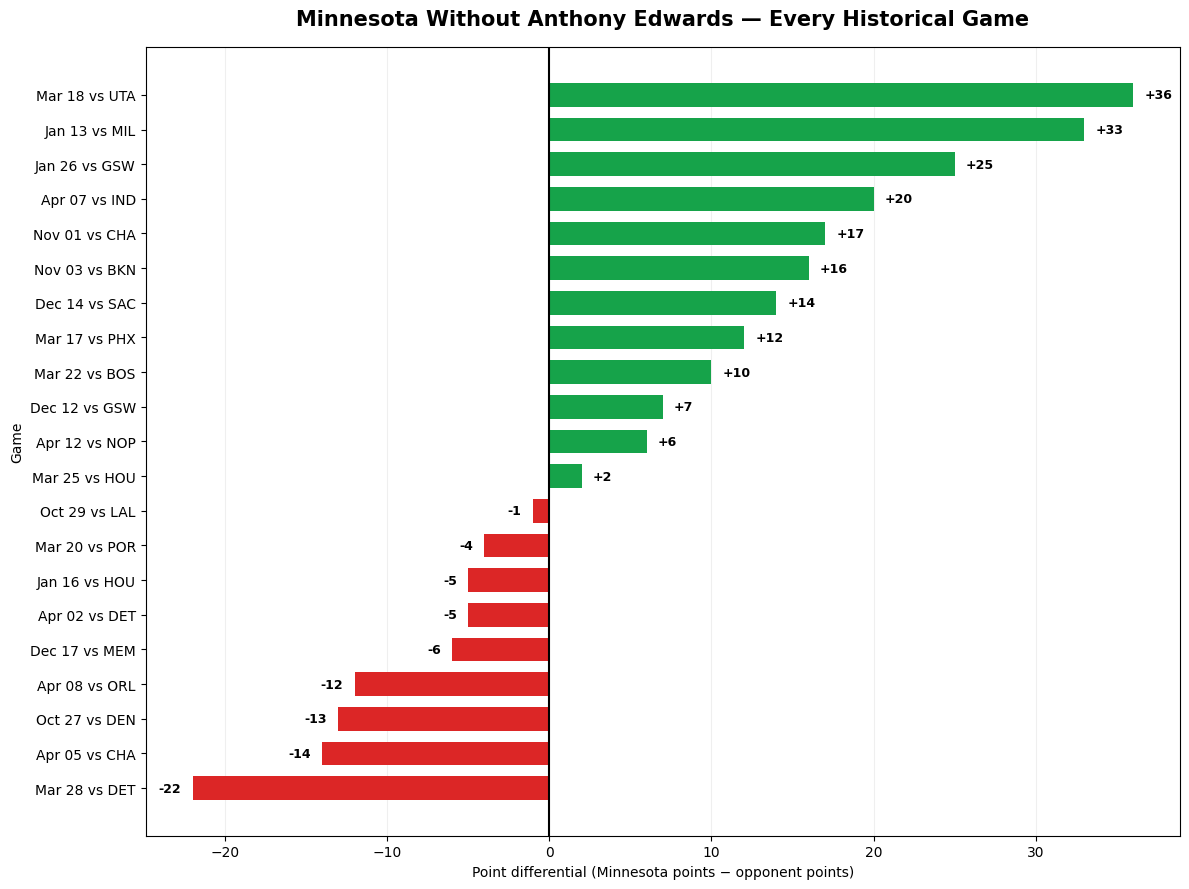

21-GAME PERFORMANCE SUMMARY
Games played:          21
Wins:                  12
Losses:                9
Win rate:              57.1%
Average winning margin: +16.50 points
Average losing margin:   -9.11 points
Overall average margin:  +5.52 points


In [ ]:
# ============================================================
# CELL 16 — HISTORICAL NO-EDWARDS GAME-BY-GAME PERFORMANCE
# ============================================================

plot_data = historical_absence_results.copy()

plot_data["Date"] = pd.to_datetime(plot_data["game_date"])
plot_data["Margin"] = plot_data["Point_Differential"].astype(float)
plot_data["Game"] = (
    plot_data["Date"].dt.strftime("%b %d")
    + " vs "
    + plot_data["opponent"].astype(str)
)

# Sort from biggest loss to biggest win
plot_data = plot_data.sort_values("Margin").reset_index(drop=True)

wins = plot_data[plot_data["Margin"] > 0]
losses = plot_data[plot_data["Margin"] < 0]

fig, ax = plt.subplots(figsize=(12, 9))

colors = [
    "#16A34A" if margin > 0 else "#DC2626"
    for margin in plot_data["Margin"]
]

bars = ax.barh(
    plot_data["Game"],
    plot_data["Margin"],
    color=colors,
    height=0.68
)

ax.axvline(0, color="black", linewidth=1.5)

# Label every game with its point differential
for bar, margin in zip(bars, plot_data["Margin"]):
    offset = 0.7 if margin >= 0 else -0.7
    alignment = "left" if margin >= 0 else "right"

    ax.text(
        margin + offset,
        bar.get_y() + bar.get_height() / 2,
        f"{margin:+.0f}",
        va="center",
        ha=alignment,
        fontsize=9,
        fontweight="bold"
    )

ax.set_title(
    "Minnesota Without Anthony Edwards — Every Historical Game",
    fontsize=15,
    fontweight="bold",
    pad=16
)

ax.set_xlabel("Point differential (Minnesota points − opponent points)")
ax.set_ylabel("Game")

ax.grid(axis="x", alpha=0.2)
ax.set_axisbelow(True)

plt.tight_layout()
plt.show()

print("=" * 60)
print("21-GAME PERFORMANCE SUMMARY")
print("=" * 60)

print(f"Games played:          {len(plot_data)}")
print(f"Wins:                  {len(wins)}")
print(f"Losses:                {len(losses)}")
print(f"Win rate:              {len(wins) / len(plot_data):.1%}")
print(f"Average winning margin:{wins['Margin'].mean():+7.2f} points")
print(f"Average losing margin: {losses['Margin'].mean():+7.2f} points")
print(f"Overall average margin:{plot_data['Margin'].mean():+7.2f} points")

**Quantify prediction uncertainty**

MODEL UNCERTAINTY — HISTORICAL NO-EDWARDS GAMES


,Metric,Value
0,Historical games,21.000
1,Mean point differential,5.520
2,Median point differential,6.000
3,Standard deviation,15.720
4,Robust standard deviation,16.310
5,95% CI — lower bound,-0.810
6,95% CI — upper bound,12.100
7,Average winning margin,16.500
8,Average losing margin,-9.110


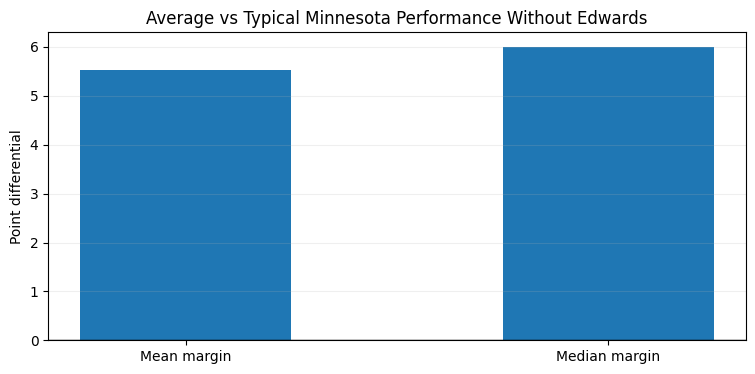


MODELLING NOTE:
Observed game-to-game standard deviation: 15.72 points
Robust volatility estimate:               16.31 points
The 95% bootstrap interval describes uncertainty in the historical
average, not the prediction interval for an individual future game.


In [ ]:
# ============================================================
# CELL 17 — MODEL UNCERTAINTY AND HISTORICAL VOLATILITY
# ============================================================

margins = historical_absence_results["Point_Differential"].astype(float)

# Basic statistics
mean_margin = margins.mean()
median_margin = margins.median()
margin_std = margins.std(ddof=1)

# Robust volatility using Median Absolute Deviation
mad = np.median(np.abs(margins - median_margin))
robust_std = 1.4826 * mad

# Bootstrap confidence interval for the mean margin
bootstrap_rng = np.random.default_rng(RANDOM_SEED)
bootstrap_means = np.array([
    bootstrap_rng.choice(margins, size=len(margins), replace=True).mean()
    for _ in range(20000)
])

ci_lower, ci_upper = np.percentile(bootstrap_means, [2.5, 97.5])

# Win/loss breakdown
winning_margins = margins[margins > 0]
losing_margins = margins[margins < 0]

uncertainty_summary = pd.DataFrame({
    "Metric": [
        "Historical games",
        "Mean point differential",
        "Median point differential",
        "Standard deviation",
        "Robust standard deviation",
        "95% CI — lower bound",
        "95% CI — upper bound",
        "Average winning margin",
        "Average losing margin"
    ],
    "Value": [
        len(margins),
        mean_margin,
        median_margin,
        margin_std,
        robust_std,
        ci_lower,
        ci_upper,
        winning_margins.mean(),
        losing_margins.mean()
    ]
})

print("=" * 65)
print("MODEL UNCERTAINTY — HISTORICAL NO-EDWARDS GAMES")
print("=" * 65)

display(uncertainty_summary.round(2))

# Visual comparison of mean and median
plt.figure(figsize=(9, 4))

plt.bar(
    ["Mean margin", "Median margin"],
    [mean_margin, median_margin],
    width=0.5
)

plt.axhline(0, color="black", linewidth=1)
plt.ylabel("Point differential")
plt.title("Average vs Typical Minnesota Performance Without Edwards")
plt.grid(axis="y", alpha=0.2)
plt.show()

print("\nMODELLING NOTE:")
print(f"Observed game-to-game standard deviation: {margin_std:.2f} points")
print(f"Robust volatility estimate:               {robust_std:.2f} points")
print("The 95% bootstrap interval describes uncertainty in the historical")
print("average, not the prediction interval for an individual future game.")

**Schedule-adjusted expected point differential**

In [ ]:
# ============================================================
# CELL 18 — SCHEDULE-ADJUSTED EXPECTED POINT DIFFERENTIAL
# ============================================================

# Model inputs established from previous analysis
BASELINE_NO_EDWARDS_RATING = 3.445
HOME_COURT_ADVANTAGE = 1.74
GAME_MARGIN_SD = 15.72

# 2025-26 opponent SRS ratings
opponent_srs_map = {
    "OKC": 11.04,
    "SAS": 8.28,
    "DET": 7.53,
    "BOS": 7.37,
    "NYK": 6.05,
    "DEN": 4.97,
    "HOU": 4.87,
    "CHA": 4.48,
    "CLE": 3.77,
    "MIN": 3.07,
    "TOR": 2.75,
    "ATL": 2.38,
    "MIA": 2.35,
    "PHX": 1.74,
    "LAL": 1.68,
    "LAC": 0.96,
    "ORL": 0.81,
    "PHI": -0.27,
    "POR": -0.28,
    "GSW": -0.34,
    "NOP": -4.26,
    "CHI": -5.09,
    "DAL": -5.33,
    "MEM": -5.83,
    "MIL": -6.12,
    "IND": -7.64,
    "UTA": -8.04,
    "SAC": -9.58,
    "BKN": -9.70,
    "WAS": -11.62
}

# Copy schedule and calculate opponent strength
forecast_schedule = schedule.copy()

forecast_schedule["Opponent_SRS"] = (
    forecast_schedule["Opponent"].map(opponent_srs_map)
)

if forecast_schedule["Opponent_SRS"].isna().any():
    missing = forecast_schedule.loc[
        forecast_schedule["Opponent_SRS"].isna(), "Opponent"
    ].unique()
    raise ValueError(f"Missing opponent SRS ratings: {missing}")

# Home-court adjustment
forecast_schedule["Venue_Adjustment"] = np.where(
    forecast_schedule["Location"].str.lower().eq("home"),
    HOME_COURT_ADVANTAGE,
    -HOME_COURT_ADVANTAGE
)

# Expected margin before rest-related adjustments
forecast_schedule["Expected_Margin"] = (
    BASELINE_NO_EDWARDS_RATING
    - forecast_schedule["Opponent_SRS"]
    + forecast_schedule["Venue_Adjustment"]
)

# First scheduled game has already been completed
forecast_schedule["Game_Status"] = np.where(
    forecast_schedule["Game_Number"] == 1,
    "COMPLETED — ACTUAL RESULT",
    "UPCOMING — MODEL ESTIMATE"
)

# Display all games
display_columns = [
    "Game_Number",
    "Date",
    "Opponent",
    "Location",
    "Opponent_SRS",
    "Venue_Adjustment",
    "Expected_Margin",
    "Game_Status"
]

print("=" * 85)
print("SCHEDULE-ADJUSTED EXPECTED POINT DIFFERENTIAL")
print("=" * 85)

display(
    forecast_schedule[display_columns].round(2)
)

upcoming = forecast_schedule[
    forecast_schedule["Game_Number"] > 1
]

print("\nSCHEDULE SUMMARY")
print(f"Completed games: {len(forecast_schedule) - len(upcoming)}")
print(f"Upcoming games:  {len(upcoming)}")
print(f"Average opponent SRS: {upcoming['Opponent_SRS'].mean():+.2f}")
print(f"Average expected margin: {upcoming['Expected_Margin'].mean():+.2f}")

print("\nNOTE:")
print("These are baseline expected margins before rest adjustments.")
print("They are not final win probabilities or guaranteed outcomes.")

SCHEDULE-ADJUSTED EXPECTED POINT DIFFERENTIAL


,Game_Number,Date,Opponent,Location,Opponent_SRS,Venue_Adjustment,Expected_Margin,Game_Status
0,1,2026-10-31,SAS,Away,8.280,-1.740,-6.570,COMPLETED — ACTUAL RESULT
1,2,2026-11-02,MIL,Home,-6.120,1.740,11.300,UPCOMING — MODEL ESTIMATE
2,3,2026-11-04,HOU,Away,4.870,-1.740,-3.160,UPCOMING — MODEL ESTIMATE
3,4,2026-11-08,UTA,Home,-8.040,1.740,13.220,UPCOMING — MODEL ESTIMATE
4,5,2026-11-12,DAL,Home,-5.330,1.740,10.520,UPCOMING — MODEL ESTIMATE
5,6,2026-11-14,CHI,Home,-5.090,1.740,10.280,UPCOMING — MODEL ESTIMATE
6,7,2026-11-16,POR,Home,-0.280,1.740,5.460,UPCOMING — MODEL ESTIMATE
7,8,2026-11-17,POR,Home,-0.280,1.740,5.460,UPCOMING — MODEL ESTIMATE
8,9,2026-11-19,NYK,Home,6.050,1.740,-0.860,UPCOMING — MODEL ESTIMATE
9,10,2026-11-21,MEM,Home,-5.830,1.740,11.020,UPCOMING — MODEL ESTIMATE



SCHEDULE SUMMARY
Completed games: 1
Upcoming games:  17
Average opponent SRS: -2.34
Average expected margin: +6.09

NOTE:
These are baseline expected margins before rest adjustments.
They are not final win probabilities or guaranteed outcomes.


**Measure Minnesota's back-to-back performance**

In [ ]:
# ============================================================
# CELL 19 — HISTORICAL BACK-TO-BACK PERFORMANCE
# ============================================================

# Reconstruct team-level game scores from historical player logs
team_game_scores = (
    historical_player_logs
    .groupby(["game_id", "game_date", "team", "opponent", "home"], as_index=False)
    .agg(Team_Points=("pts", "sum"))
)

# Isolate Minnesota games
min_history = team_game_scores[
    team_game_scores["team"] == "MIN"
].copy()

min_history["game_date"] = pd.to_datetime(min_history["game_date"])
min_history = min_history.sort_values("game_date").reset_index(drop=True)

# Calculate opponent scores from the opponent's matching game record
opponent_scores = team_game_scores[
    ["game_id", "team", "Team_Points"]
].rename(columns={
    "team": "opponent",
    "Team_Points": "Opponent_Points"
})

min_history = min_history.merge(
    opponent_scores,
    on=["game_id", "opponent"],
    how="left"
)

min_history["Point_Differential"] = (
    min_history["Team_Points"] - min_history["Opponent_Points"]
)

# Calculate rest days between Minnesota games
min_history["Days_Between_Games"] = (
    min_history["game_date"].diff().dt.days
)

min_history["Back_To_Back"] = (
    min_history["Days_Between_Games"] == 1
)

# Performance comparison
rest_summary = (
    min_history
    .groupby("Back_To_Back")
    .agg(
        Games=("game_id", "count"),
        Wins=("Point_Differential", lambda x: (x > 0).sum()),
        Average_Margin=("Point_Differential", "mean"),
        Median_Margin=("Point_Differential", "median"),
        Margin_Std=("Point_Differential", "std")
    )
    .reset_index()
)

rest_summary["Win_Rate"] = (
    rest_summary["Wins"] / rest_summary["Games"] * 100
)

rest_summary["Game_Type"] = rest_summary["Back_To_Back"].map({
    True: "Back-to-back",
    False: "One or more rest days"
})

print("=" * 70)
print("MINNESOTA — BACK-TO-BACK PERFORMANCE (2025-26)")
print("=" * 70)

display(
    rest_summary[
        [
            "Game_Type",
            "Games",
            "Wins",
            "Win_Rate",
            "Average_Margin",
            "Median_Margin",
            "Margin_Std"
        ]
    ].round(2)
)

# Estimate the observed difference
b2b_margin = min_history.loc[
    min_history["Back_To_Back"], "Point_Differential"
].mean()

normal_margin = min_history.loc[
    ~min_history["Back_To_Back"], "Point_Differential"
].mean()

print("\nOBSERVED BACK-TO-BACK MARGIN DIFFERENCE")
print(f"Back-to-back average margin: {b2b_margin:+.2f}")
print(f"Rested-game average margin:  {normal_margin:+.2f}")
print(f"Observed difference:        {b2b_margin - normal_margin:+.2f}")

print("\nCAUTION:")
print("This is a descriptive comparison, not a causal fatigue estimate.")
print("Opponent quality, injuries and player availability may differ.")

MINNESOTA — BACK-TO-BACK PERFORMANCE (2025-26)


,Game_Type,Games,Wins,Win_Rate,Average_Margin,Median_Margin,Margin_Std
0,One or more rest days,68,41,60.290,3.070,4.000,15.370
1,Back-to-back,14,8,57.140,4.710,4.000,18.280



OBSERVED BACK-TO-BACK MARGIN DIFFERENCE
Back-to-back average margin: +4.71
Rested-game average margin:  +3.07
Observed difference:        +1.64

CAUTION:
This is a descriptive comparison, not a causal fatigue estimate.
Opponent quality, injuries and player availability may differ.


**Simulate all 17 upcoming games**

In [ ]:
# ============================================================
# CELL 20 — MONTE CARLO SIMULATION: 17 UPCOMING GAMES
# ============================================================

N_SIMULATIONS = 100_000
GAME_MARGIN_SD = 15.72

# Exclude the completed San Antonio game
upcoming_games = (
    forecast_schedule[
        forecast_schedule["Game_Number"] > 1
    ].copy()
    .reset_index(drop=True)
)

# Expected margins for each upcoming game
expected_margins = upcoming_games["Expected_Margin"].to_numpy()

# Simulate game margins
simulation_rng = np.random.default_rng(RANDOM_SEED)

simulated_margins = simulation_rng.normal(
    loc=expected_margins,
    scale=GAME_MARGIN_SD,
    size=(N_SIMULATIONS, len(upcoming_games))
)

# Determine game outcomes
simulated_wins = simulated_margins > 0
simulated_losses = simulated_margins < 0

# Calculate outcomes for each simulation
simulated_total_wins = simulated_wins.sum(axis=1)
simulated_total_losses = simulated_losses.sum(axis=1)

# Game-level probabilities
upcoming_games["Win_Probability"] = (
    simulated_wins.mean(axis=0) * 100
)

upcoming_games["Loss_Probability"] = (
    simulated_losses.mean(axis=0) * 100
)

upcoming_games["Expected_Margin"] = expected_margins

# Distribution of total wins
win_counts = pd.Series(simulated_total_wins).value_counts().sort_index()

# Summary statistics
average_wins = simulated_total_wins.mean()
median_wins = np.median(simulated_total_wins)

wins_ci_lower, wins_ci_upper = np.percentile(
    simulated_total_wins,
    [2.5, 97.5]
)

# Display game-by-game probabilities
print("=" * 75)
print("MONTE CARLO — GAME-BY-GAME WIN PROBABILITIES")
print("=" * 75)

display(
    upcoming_games[
        [
            "Game_Number",
            "Date",
            "Opponent",
            "Location",
            "Expected_Margin",
            "Win_Probability",
            "Loss_Probability"
        ]
    ].round(2)
)

print("\n" + "=" * 75)
print("17-GAME SIMULATION SUMMARY")
print("=" * 75)

print(f"Simulations:              {N_SIMULATIONS:,}")
print(f"Expected wins:            {average_wins:.2f}")
print(f"Median wins:              {median_wins:.0f}")
print(f"Expected losses:          {17 - average_wins:.2f}")
print(f"95% range of total wins:  {wins_ci_lower:.0f} to {wins_ci_upper:.0f}")

print("\nMOST COMMON WIN TOTALS")
display(
    win_counts.sort_values(ascending=False)
    .head(10)
    .rename("Simulations")
    .to_frame()
)

MONTE CARLO — GAME-BY-GAME WIN PROBABILITIES


,Game_Number,Date,Opponent,Location,Expected_Margin,Win_Probability,Loss_Probability
0,2,2026-11-02,MIL,Home,11.300,76.430,23.570
1,3,2026-11-04,HOU,Away,-3.160,42.080,57.920
2,4,2026-11-08,UTA,Home,13.220,80.030,19.970
3,5,2026-11-12,DAL,Home,10.520,75.080,24.920
4,6,2026-11-14,CHI,Home,10.280,74.330,25.670
5,7,2026-11-16,POR,Home,5.460,63.440,36.560
6,8,2026-11-17,POR,Home,5.460,63.620,36.380
7,9,2026-11-19,NYK,Home,-0.860,47.820,52.180
8,10,2026-11-21,MEM,Home,11.020,75.960,24.040
9,11,2026-11-23,BKN,Home,14.880,82.800,17.200



17-GAME SIMULATION SUMMARY
Simulations:              100,000
Expected wins:            10.92
Median wins:              11
Expected losses:          6.08
95% range of total wins:  7 to 14

MOST COMMON WIN TOTALS


,Simulations
11,20948
12,18598
10,18299
9,12281
13,12162
8,6245
14,5678
7,2609
15,1814
6,785


**Account for uncertainty in team strength**

In [ ]:
# ============================================================
# CELL 21 — CORRECTED TEAM RATING UNCERTAINTY
# ============================================================

N_SIMULATIONS = 100_000
N_BOOTSTRAPS = 20_000

# ------------------------------------------------------------
# 1. HISTORICAL NO-EDWARDS TEAM RATINGS
# ------------------------------------------------------------

historical_venue = np.where(
    historical_absence_results["home"].astype(bool),
    HOME_COURT_ADVANTAGE,
    -HOME_COURT_ADVANTAGE
)

historical_ratings = (
    historical_absence_results["Point_Differential"].astype(float)
    + historical_absence_results["opponent"].map(opponent_srs_map)
    - historical_venue
).to_numpy()

# ------------------------------------------------------------
# 2. CURRENT-SEASON NO-EDWARDS TEAM RATINGS
# ------------------------------------------------------------

current_venue = np.where(
    current_season_results["Location"].str.lower().eq("home"),
    HOME_COURT_ADVANTAGE,
    -HOME_COURT_ADVANTAGE
)

current_ratings = (
    current_season_results["Point_Differential"].astype(float)
    + current_season_results["Opponent"].map(opponent_srs_map)
    - current_venue
).to_numpy()

if np.isnan(historical_ratings).any() or np.isnan(current_ratings).any():
    raise ValueError("Missing opponent SRS ratings.")

# ------------------------------------------------------------
# 3. VALIDATE AGAINST ESTABLISHED BASELINE
# ------------------------------------------------------------

historical_rating = historical_ratings.mean()
current_rating = current_ratings.mean()

corrected_baseline = (
    PRIOR_SEASON_WEIGHT * historical_rating
    + CURRENT_SEASON_WEIGHT * current_rating
)

print("=" * 70)
print("CORRECTED TEAM RATINGS")
print("=" * 70)

print(f"Historical rating:       {historical_rating:+.3f}")
print(f"Current-season rating:   {current_rating:+.3f}")
print(f"Weighted baseline:       {corrected_baseline:+.3f}")
print(f"Previously established:  {BASELINE_NO_EDWARDS_RATING:+.3f}")

# ------------------------------------------------------------
# 4. BOOTSTRAP TEAM-RATING UNCERTAINTY
# ------------------------------------------------------------

bootstrap_rng = np.random.default_rng(RANDOM_SEED)

historical_bootstrap = bootstrap_rng.choice(
    historical_ratings,
    size=(N_BOOTSTRAPS, len(historical_ratings)),
    replace=True
).mean(axis=1)

current_bootstrap = bootstrap_rng.choice(
    current_ratings,
    size=(N_BOOTSTRAPS, len(current_ratings)),
    replace=True
).mean(axis=1)

bootstrap_team_ratings = (
    PRIOR_SEASON_WEIGHT * historical_bootstrap
    + CURRENT_SEASON_WEIGHT * current_bootstrap
)

print("\nBOOTSTRAP RATING DISTRIBUTION")

print(
    f"Mean: {bootstrap_team_ratings.mean():+.2f}\n"
    f"Median: {np.median(bootstrap_team_ratings):+.2f}\n"
    f"95% range: "
    f"{np.percentile(bootstrap_team_ratings, 2.5):+.2f} to "
    f"{np.percentile(bootstrap_team_ratings, 97.5):+.2f}"
)

# ------------------------------------------------------------
# 5. SIMULATE TEAM STRENGTH AND GAME OUTCOMES
# ------------------------------------------------------------

simulation_rng = np.random.default_rng(RANDOM_SEED + 1)

rating_draws = simulation_rng.choice(
    bootstrap_team_ratings,
    size=N_SIMULATIONS,
    replace=True
)

venue_and_opponent = (
    -upcoming_games["Opponent_SRS"].to_numpy()
    + upcoming_games["Venue_Adjustment"].to_numpy()
)

uncertain_expected_margins = (
    rating_draws[:, None]
    + venue_and_opponent[None, :]
)

uncertain_simulated_margins = simulation_rng.normal(
    loc=uncertain_expected_margins,
    scale=GAME_MARGIN_SD,
    size=(N_SIMULATIONS, len(upcoming_games))
)

uncertain_wins = uncertain_simulated_margins > 0
uncertain_total_wins = uncertain_wins.sum(axis=1)

# ------------------------------------------------------------
# 6. GAME-LEVEL PROBABILITIES
# ------------------------------------------------------------

comparison = upcoming_games[
    ["Game_Number", "Date", "Opponent", "Location"]
].copy()

comparison["Expected_Margin"] = (
    corrected_baseline + venue_and_opponent
)

comparison["Win_Probability"] = (
    uncertain_wins.mean(axis=0) * 100
)

comparison["Loss_Probability"] = (
    100 - comparison["Win_Probability"]
)

print("\n" + "=" * 70)
print("CORRECTED GAME-BY-GAME FORECAST")
print("=" * 70)

display(comparison.round(2))

# ------------------------------------------------------------
# 7. TOTAL SERIES FORECAST
# ------------------------------------------------------------

print("\n" + "=" * 70)
print("CORRECTED 17-GAME FORECAST")
print("=" * 70)

print(f"Expected wins: {uncertain_total_wins.mean():.2f}")
print(f"Median wins:   {np.median(uncertain_total_wins):.0f}")
print(
    f"95% range:    "
    f"{np.percentile(uncertain_total_wins, 2.5):.0f} to "
    f"{np.percentile(uncertain_total_wins, 97.5):.0f}"
)

print("\nMOST COMMON WIN TOTALS")

display(
    pd.Series(uncertain_total_wins)
    .value_counts()
    .sort_values(ascending=False)
    .head(10)
    .rename("Simulations")
    .to_frame()
)

CORRECTED TEAM RATINGS
Historical rating:       +5.190
Current-season rating:   +12.350
Weighted baseline:       +6.622
Previously established:  +3.445

BOOTSTRAP RATING DISTRIBUTION
Mean: +6.64
Median: +6.62
95% range: +1.63 to +11.66

CORRECTED GAME-BY-GAME FORECAST


,Game_Number,Date,Opponent,Location,Expected_Margin,Win_Probability,Loss_Probability
0,2,2026-11-02,MIL,Home,14.480,81.660,18.340
1,3,2026-11-04,HOU,Away,0.010,50.090,49.910
2,4,2026-11-08,UTA,Home,16.400,84.690,15.310
3,5,2026-11-12,DAL,Home,13.690,80.540,19.470
4,6,2026-11-14,CHI,Home,13.450,80.290,19.710
5,7,2026-11-16,POR,Home,8.640,70.840,29.160
6,8,2026-11-17,POR,Home,8.640,70.840,29.160
7,9,2026-11-19,NYK,Home,2.310,55.880,44.120
8,10,2026-11-21,MEM,Home,14.190,81.500,18.500
9,11,2026-11-23,BKN,Home,18.060,87.020,12.980



CORRECTED 17-GAME FORECAST
Expected wins: 12.01
Median wins:   12
95% range:    8 to 16

MOST COMMON WIN TOTALS


,Simulations
12,19832
13,19004
11,16408
14,13625
10,11015
15,6900
9,6223
8,2852
16,2306
7,1064


**Audit current-season rating calculations**

In [ ]:
# ============================================================
# CELL 22 — AUDIT CURRENT-SEASON TEAM RATING
# ============================================================

audit = current_season_results.copy()

audit["Opponent_SRS"] = audit["Opponent"].map(opponent_srs_map)

audit["Venue_Adjustment"] = np.where(
    audit["Location"].str.lower().eq("home"),
    HOME_COURT_ADVANTAGE,
    -HOME_COURT_ADVANTAGE
)

# Recalculate point differential directly from scores
audit["Recalculated_Margin"] = (
    audit["Team_Points"] - audit["Opponent_Points"]
)

# Correct team rating formula
audit["Recalculated_Team_Rating"] = (
    audit["Recalculated_Margin"]
    + audit["Opponent_SRS"]
    - audit["Venue_Adjustment"]
)

print("=" * 75)
print("CURRENT-SEASON RATING AUDIT")
print("=" * 75)

display(
    audit[
        [
            "Date",
            "Opponent",
            "Location",
            "Team_Points",
            "Opponent_Points",
            "Point_Differential",
            "Recalculated_Margin",
            "Opponent_SRS",
            "Venue_Adjustment",
            "Recalculated_Team_Rating"
        ]
    ].round(2)
)

print("\n" + "=" * 75)
print("RATING VALIDATION")
print("=" * 75)

print(
    "Stored point differential average:",
    round(audit["Point_Differential"].mean(), 2)
)

print(
    "Recalculated point differential average:",
    round(audit["Recalculated_Margin"].mean(), 2)
)

print(
    "Recalculated current-season rating:",
    round(audit["Recalculated_Team_Rating"].mean(), 3)
)

print(
    "Corrected weighted baseline:",
    round(
        PRIOR_SEASON_WEIGHT * historical_ratings.mean()
        + CURRENT_SEASON_WEIGHT * audit["Recalculated_Team_Rating"].mean(),
        3
    )
)

CURRENT-SEASON RATING AUDIT


,Date,Opponent,Location,Team_Points,Opponent_Points,Point_Differential,Recalculated_Margin,Opponent_SRS,Venue_Adjustment,Recalculated_Team_Rating
0,2026-10-21,MIA,Away,131,106,25,25,2.350,-1.740,29.090
1,2026-10-23,ORL,Away,115,93,22,22,0.810,-1.740,24.550
2,2026-10-25,TOR,Home,117,94,23,23,2.750,1.740,24.010
3,2026-10-26,CLE,Away,125,127,-2,-2,3.770,-1.740,3.510
4,2026-10-28,GSW,Home,114,119,-5,-5,-0.340,1.740,-7.080
5,2026-10-31,SAS,Away,111,121,-10,-10,8.280,-1.740,0.020



RATING VALIDATION
Stored point differential average: 8.83
Recalculated point differential average: 8.83
Recalculated current-season rating: 12.35
Corrected weighted baseline: 6.622


**Correctly isolate games without Edwards**

In [ ]:
# ============================================================
# CELL 23 — CURRENT-SEASON NO-EDWARDS RATING
# ============================================================

# Only include games where Anthony Edwards was absent
current_absence_only = current_season_results[
    current_season_results["Edwards_Status"].str.lower().eq("absent")
].copy()

current_absence_only["Opponent_SRS"] = (
    current_absence_only["Opponent"].map(opponent_srs_map)
)

current_absence_only["Venue_Adjustment"] = np.where(
    current_absence_only["Location"].str.lower().eq("home"),
    HOME_COURT_ADVANTAGE,
    -HOME_COURT_ADVANTAGE
)

current_absence_only["Adjusted_Team_Rating"] = (
    current_absence_only["Point_Differential"]
    + current_absence_only["Opponent_SRS"]
    - current_absence_only["Venue_Adjustment"]
)

current_rating_corrected = (
    current_absence_only["Adjusted_Team_Rating"].mean()
)

historical_rating_corrected = historical_ratings.mean()

weighted_baseline_corrected = (
    PRIOR_SEASON_WEIGHT * historical_rating_corrected
    + CURRENT_SEASON_WEIGHT * current_rating_corrected
)

print("=" * 75)
print("NO-EDWARDS RATING — CORRECTED")
print("=" * 75)

display(
    current_absence_only[
        [
            "Date",
            "Opponent",
            "Location",
            "Point_Differential",
            "Opponent_SRS",
            "Venue_Adjustment",
            "Adjusted_Team_Rating"
        ]
    ].round(3)
)

print("\nHistorical rating:", round(historical_rating_corrected, 3))
print("Current no-Edwards rating:", round(current_rating_corrected, 3))
print("Weighted baseline:", round(weighted_baseline_corrected, 3))

print("\nGames included:", len(current_absence_only))

NO-EDWARDS RATING — CORRECTED


,Date,Opponent,Location,Point_Differential,Opponent_SRS,Venue_Adjustment,Adjusted_Team_Rating
4,2026-10-28,GSW,Home,-5,-0.340,1.740,-7.080
5,2026-10-31,SAS,Away,-10,8.280,-1.740,0.020



Historical rating: 5.19
Current no-Edwards rating: -3.53
Weighted baseline: 3.446

Games included: 2


**Final corrected 17-game simulation**

In [ ]:
# ============================================================
# CELL 24 — CORRECTED PARAMETER-UNCERTAINTY SIMULATION
# ============================================================

simulation_rng = np.random.default_rng(RANDOM_SEED)

# 1. Prepare the 17 remaining games
future_schedule = schedule[
    schedule["Game_Number"] > 1
].copy().reset_index(drop=True)

future_schedule["Opponent_SRS"] = (
    future_schedule["Opponent"].map(opponent_srs_map)
)

future_schedule["Venue_Adjustment"] = np.where(
    future_schedule["Location"].str.lower().eq("home"),
    HOME_COURT_ADVANTAGE,
    -HOME_COURT_ADVANTAGE
)

# 2. Validate rating inputs
historical_values = np.asarray(
    historical_ratings, dtype=float
)
historical_values = historical_values[
    np.isfinite(historical_values)
]

current_values = (
    current_absence_only["Adjusted_Team_Rating"]
    .to_numpy(dtype=float)
)

current_values = current_values[
    np.isfinite(current_values)
]

assert len(historical_values) == 21
assert len(current_values) == 2
assert len(future_schedule) == 17

# 3. Calculate corrected baseline
historical_mean = historical_values.mean()
current_mean = current_values.mean()

baseline_rating = (
    PRIOR_SEASON_WEIGHT * historical_mean
    + CURRENT_SEASON_WEIGHT * current_mean
)

# 4. Estimate game-level variation
margin_std = historical_absence_results[
    "Point_Differential"
].std(ddof=1)

# 5. Bootstrap rating uncertainty
historical_bootstrap = simulation_rng.choice(
    historical_values,
    size=(N_SIMULATIONS, len(historical_values)),
    replace=True
).mean(axis=1)

current_bootstrap = simulation_rng.choice(
    current_values,
    size=(N_SIMULATIONS, len(current_values)),
    replace=True
).mean(axis=1)

rating_bootstrap = (
    PRIOR_SEASON_WEIGHT * historical_bootstrap
    + CURRENT_SEASON_WEIGHT * current_bootstrap
)

# 6. Calculate expected margins
opponent_srs = future_schedule[
    "Opponent_SRS"
].to_numpy(dtype=float)

venue_adjustments = future_schedule[
    "Venue_Adjustment"
].to_numpy(dtype=float)

expected_margins = (
    baseline_rating
    - opponent_srs
    + venue_adjustments
)

# 7. Simulate 17 games
simulated_margins = (
    rating_bootstrap[:, None]
    - opponent_srs[None, :]
    + venue_adjustments[None, :]
    + simulation_rng.normal(
        0,
        margin_std,
        size=(N_SIMULATIONS, len(future_schedule))
    )
)

simulated_wins = (
    simulated_margins > 0
).sum(axis=1)

# 8. Game-level probabilities
future_schedule["Expected_Margin"] = expected_margins

future_schedule["Win_Probability"] = (
    (simulated_margins > 0).mean(axis=0) * 100
)

future_schedule["Loss_Probability"] = (
    100 - future_schedule["Win_Probability"]
)

# 9. Aggregate forecast
expected_wins = simulated_wins.mean()
median_wins = np.median(simulated_wins)

lower_bound, upper_bound = np.percentile(
    simulated_wins,
    [2.5, 97.5]
)

print("=" * 75)
print("CORRECTED MODEL VALIDATION")
print("=" * 75)

print(f"Historical rating: {historical_mean:+.3f}")
print(f"Current no-Edwards rating: {current_mean:+.3f}")
print(f"Weighted baseline: {baseline_rating:+.3f}")
print(f"Game-level SD: {margin_std:.3f}")
print(f"Games forecast: {len(future_schedule)}")

print("\n" + "=" * 75)
print("GAME-BY-GAME FORECAST")
print("=" * 75)

display(
    future_schedule[
        [
            "Game_Number",
            "Date",
            "Opponent",
            "Location",
            "Expected_Margin",
            "Win_Probability",
            "Loss_Probability"
        ]
    ].round(2)
)

print("\n" + "=" * 75)
print("17-GAME FORECAST")
print("=" * 75)

print(f"Expected wins: {expected_wins:.2f}")
print(f"Median wins: {median_wins:.0f}")
print(f"95% range: {lower_bound:.0f} to {upper_bound:.0f}")

print("\nMOST COMMON WIN TOTALS")

win_distribution = (
    pd.Series(simulated_wins)
    .value_counts()
    .sort_values(ascending=False)
    .head(10)
)

display(
    win_distribution.rename_axis("Wins").to_frame("Simulations")
)

CORRECTED MODEL VALIDATION
Historical rating: +5.190
Current no-Edwards rating: -3.530
Weighted baseline: +3.446
Game-level SD: 15.715
Games forecast: 17

GAME-BY-GAME FORECAST


,Game_Number,Date,Opponent,Location,Expected_Margin,Win_Probability,Loss_Probability
0,2,2026-11-02,MIL,Home,11.310,76.220,23.780
1,3,2026-11-04,HOU,Away,-3.160,42.190,57.810
2,4,2026-11-08,UTA,Home,13.230,79.820,20.190
3,5,2026-11-12,DAL,Home,10.520,74.540,25.460
4,6,2026-11-14,CHI,Home,10.280,74.090,25.910
5,7,2026-11-16,POR,Home,5.470,63.380,36.620
6,8,2026-11-17,POR,Home,5.470,63.540,36.460
7,9,2026-11-19,NYK,Home,-0.860,47.950,52.050
8,10,2026-11-21,MEM,Home,11.020,75.800,24.200
9,11,2026-11-23,BKN,Home,14.890,82.540,17.460



17-GAME FORECAST
Expected wins: 10.89
Median wins: 11
95% range: 7 to 15

MOST COMMON WIN TOTALS


,Simulations
Wins,
11,18968
12,17216
10,16759
13,12346
9,12217
8,7065
14,6757
7,3512
15,2578


**Test the weighting assumptions**

WEIGHT SENSITIVITY — 17 REMAINING GAMES


,Historical_Weight,Current_Weight,Baseline_Rating,Expected_Wins,Median_Wins,95%_Lower,95%_Upper
0,100%,0%,5.190,11.500,12.000,7.000,15.000
1,90%,10%,4.320,11.200,11.000,7.000,15.000
2,80%,20%,3.450,10.890,11.000,7.000,15.000
3,70%,30%,2.570,10.570,11.000,6.000,14.000
4,50%,50%,0.830,9.900,10.000,6.000,14.000
5,0%,100%,-3.530,8.200,8.000,4.000,12.000


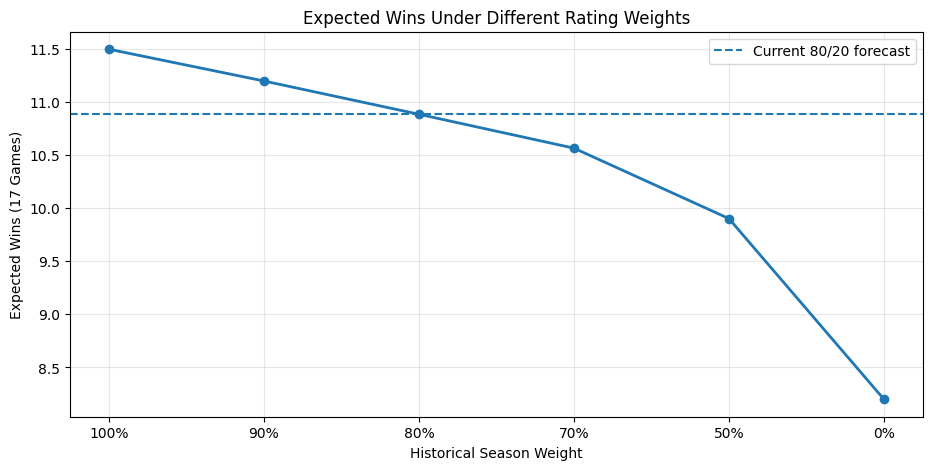

In [ ]:
# ============================================================
# CELL 25 — WEIGHT SENSITIVITY ANALYSIS
# ============================================================

sensitivity_rng = np.random.default_rng(RANDOM_SEED + 25)

# Bootstrap historical and current ratings
hist_boot = sensitivity_rng.choice(
    historical_values,
    size=(N_SIMULATIONS, len(historical_values)),
    replace=True
).mean(axis=1)

curr_boot = sensitivity_rng.choice(
    current_values,
    size=(N_SIMULATIONS, len(current_values)),
    replace=True
).mean(axis=1)

# Common game-level noise for every scenario
common_game_noise = sensitivity_rng.normal(
    0,
    margin_std,
    size=(N_SIMULATIONS, len(future_schedule))
)

weights_to_test = [1.00, 0.90, 0.80, 0.70, 0.50, 0.00]

sensitivity_results = []

for hist_weight in weights_to_test:

    current_weight = 1 - hist_weight

    # Rating distribution
    rating_samples = (
        hist_weight * hist_boot
        + current_weight * curr_boot
    )

    baseline = (
        hist_weight * historical_mean
        + current_weight * current_mean
    )

    # Simulate the 17-game schedule
    margins = (
        rating_samples[:, None]
        - opponent_srs[None, :]
        + venue_adjustments[None, :]
        + common_game_noise
    )

    wins = (margins > 0).sum(axis=1)

    lower, upper = np.percentile(wins, [2.5, 97.5])

    sensitivity_results.append({
        "Historical_Weight": f"{hist_weight:.0%}",
        "Current_Weight": f"{current_weight:.0%}",
        "Baseline_Rating": baseline,
        "Expected_Wins": wins.mean(),
        "Median_Wins": np.median(wins),
        "95%_Lower": lower,
        "95%_Upper": upper
    })

sensitivity_df = pd.DataFrame(sensitivity_results)

print("=" * 75)
print("WEIGHT SENSITIVITY — 17 REMAINING GAMES")
print("=" * 75)

display(sensitivity_df.round(2))

# Visualise sensitivity
plt.figure(figsize=(11, 5))

plt.plot(
    sensitivity_df["Historical_Weight"],
    sensitivity_df["Expected_Wins"],
    marker="o",
    linewidth=2
)

plt.axhline(
    expected_wins,
    linestyle="--",
    label="Current 80/20 forecast"
)

plt.title("Expected Wins Under Different Rating Weights")
plt.xlabel("Historical Season Weight")
plt.ylabel("Expected Wins (17 Games)")
plt.grid(alpha=0.3)
plt.legend()
plt.show()

**Validate game-level uncertainty**

In [ ]:
# ============================================================
# CELL 26 — GAME-LEVEL UNCERTAINTY VALIDATION
# ============================================================

# Historical opponent strength and venue adjustments
historical_check = historical_absence_results.copy()

historical_check["Opponent_SRS"] = (
    historical_check["opponent"].map(opponent_srs_map)
)

historical_check["Venue_Adjustment"] = np.where(
    historical_check["home"].astype(bool),
    HOME_COURT_ADVANTAGE,
    -HOME_COURT_ADVANTAGE
)

# Opponent-adjusted historical team ratings
historical_check["Adjusted_Rating"] = (
    historical_check["Point_Differential"]
    + historical_check["Opponent_SRS"]
    - historical_check["Venue_Adjustment"]
)

# Residuals around the historical average rating
historical_check["Model_Residual"] = (
    historical_check["Adjusted_Rating"]
    - historical_check["Adjusted_Rating"].mean()
)

# Calculate uncertainty measures
raw_margin_sd = historical_check["Point_Differential"].std(ddof=1)

adjusted_rating_sd = historical_check["Adjusted_Rating"].std(ddof=1)

robust_sigma = (
    1.4826
    * np.median(
        np.abs(
            historical_check["Model_Residual"]
            - np.median(historical_check["Model_Residual"])
        )
    )
)

uncertainty_comparison = pd.DataFrame({
    "Method": [
        "Raw point-margin standard deviation",
        "Opponent-adjusted residual standard deviation",
        "Robust residual standard deviation (MAD)"
    ],
    "Estimated_SD": [
        raw_margin_sd,
        adjusted_rating_sd,
        robust_sigma
    ]
})

print("=" * 75)
print("GAME-LEVEL UNCERTAINTY COMPARISON")
print("=" * 75)

display(uncertainty_comparison.round(3))

print("\nHistorical sample:", len(historical_check), "games")

print(
    "\nCurrent simulation SD:",
    round(margin_std, 3)
)

print(
    "Opponent-adjusted SD:",
    round(adjusted_rating_sd, 3)
)

print(
    "Robust SD:",
    round(robust_sigma, 3)
)

GAME-LEVEL UNCERTAINTY COMPARISON


,Method,Estimated_SD
0,Raw point-margin standard deviation,15.715
1,Opponent-adjusted residual standard deviation,13.599
2,Robust residual standard deviation (MAD),15.256



Historical sample: 21 games

Current simulation SD: 15.715
Opponent-adjusted SD: 13.599
Robust SD: 15.256


**Compare forecast uncertainty assumptions**

In [ ]:
# ============================================================
# CELL 27 — FORECAST UNCERTAINTY SCENARIO COMPARISON
# ============================================================

uncertainty_scenarios = {
    "Opponent-adjusted SD": adjusted_rating_sd,
    "Robust MAD SD": robust_sigma,
    "Original raw-margin SD": raw_margin_sd
}

scenario_results = []
scenario_game_probabilities = {}

for scenario_name, scenario_sd in uncertainty_scenarios.items():

    scenario_rng = np.random.default_rng(RANDOM_SEED + 27)

    # Keep the same rating uncertainty distribution
    rating_samples = rating_bootstrap

    # Simulate game margins
    scenario_margins = (
        rating_samples[:, None]
        - opponent_srs[None, :]
        + venue_adjustments[None, :]
        + scenario_rng.normal(
            0,
            scenario_sd,
            size=(N_SIMULATIONS, len(future_schedule))
        )
    )

    scenario_wins = (
        scenario_margins > 0
    ).sum(axis=1)

    lower, upper = np.percentile(
        scenario_wins,
        [2.5, 97.5]
    )

    scenario_results.append({
        "Uncertainty_Model": scenario_name,
        "Game_SD": scenario_sd,
        "Expected_Wins": scenario_wins.mean(),
        "Median_Wins": np.median(scenario_wins),
        "95%_Lower": lower,
        "95%_Upper": upper
    })

    scenario_game_probabilities[scenario_name] = (
        (scenario_margins > 0).mean(axis=0) * 100
    )

uncertainty_comparison_df = pd.DataFrame(
    scenario_results
)

print("=" * 75)
print("UNCERTAINTY SCENARIO COMPARISON")
print("=" * 75)

display(
    uncertainty_comparison_df.round(2)
)

# Compare game-level win probabilities
probability_comparison = future_schedule[
    ["Game_Number", "Date", "Opponent", "Location"]
].copy()

for scenario_name, probabilities in scenario_game_probabilities.items():
    probability_comparison[scenario_name] = probabilities

print("\n" + "=" * 75)
print("GAME-LEVEL WIN PROBABILITY COMPARISON")
print("=" * 75)

display(probability_comparison.round(2))

UNCERTAINTY SCENARIO COMPARISON


,Uncertainty_Model,Game_SD,Expected_Wins,Median_Wins,95%_Lower,95%_Upper
0,Opponent-adjusted SD,13.600,11.190,11.000,7.000,15.000
1,Robust MAD SD,15.260,10.950,11.000,7.000,15.000
2,Original raw-margin SD,15.720,10.900,11.000,7.000,15.000



GAME-LEVEL WIN PROBABILITY COMPARISON


,Game_Number,Date,Opponent,Location,Opponent-adjusted SD,Robust MAD SD,Original raw-margin SD
0,2,2026-11-02,MIL,Home,79.460,76.900,76.270
1,3,2026-11-04,HOU,Away,40.810,41.730,42.000
2,4,2026-11-08,UTA,Home,83.330,80.660,79.980
3,5,2026-11-12,DAL,Home,77.810,75.330,74.690
4,6,2026-11-14,CHI,Home,77.320,74.910,74.320
5,7,2026-11-16,POR,Home,65.390,63.880,63.490
6,8,2026-11-17,POR,Home,65.440,63.910,63.540
7,9,2026-11-19,NYK,Home,47.560,47.820,47.870
8,10,2026-11-21,MEM,Home,78.630,76.010,75.350
9,11,2026-11-23,BKN,Home,86.030,83.250,82.550


**Lock the primary forecast**

In [ ]:
# ============================================================
# CELL 28 — FINAL PRIMARY MODEL CONFIGURATION
# ============================================================

FINAL_GAME_SD = adjusted_rating_sd
FINAL_BASELINE_RATING = baseline_rating

final_rng = np.random.default_rng(RANDOM_SEED + 28)

# Bootstrap rating uncertainty
final_rating_samples = rating_bootstrap

# Simulate 17 remaining games
final_simulated_margins = (
    final_rating_samples[:, None]
    - opponent_srs[None, :]
    + venue_adjustments[None, :]
    + final_rng.normal(
        0,
        FINAL_GAME_SD,
        size=(N_SIMULATIONS, len(future_schedule))
    )
)

final_simulated_wins = (
    final_simulated_margins > 0
).sum(axis=1)

# Game-level probabilities
final_win_probabilities = (
    final_simulated_margins > 0
).mean(axis=0) * 100

final_loss_probabilities = 100 - final_win_probabilities

final_forecast = future_schedule[
    ["Game_Number", "Date", "Opponent", "Location"]
].copy()

final_forecast["Expected_Margin"] = (
    FINAL_BASELINE_RATING
    - opponent_srs
    + venue_adjustments
)

final_forecast["Win_Probability"] = final_win_probabilities
final_forecast["Loss_Probability"] = final_loss_probabilities

# Aggregate simulation results
final_expected_wins = final_simulated_wins.mean()
final_median_wins = np.median(final_simulated_wins)

final_lower, final_upper = np.percentile(
    final_simulated_wins,
    [2.5, 97.5]
)

# Include completed San Antonio loss
completed_games = 1
completed_wins = 0
completed_losses = 1

total_expected_wins = completed_wins + final_expected_wins
total_expected_losses = (
    completed_losses + len(future_schedule) - final_expected_wins
)

print("=" * 75)
print("FINAL MODEL CONFIGURATION")
print("=" * 75)

print(f"Historical weight:       {PRIOR_SEASON_WEIGHT:.0%}")
print(f"Current-season weight:   {CURRENT_SEASON_WEIGHT:.0%}")
print(f"Baseline rating:         {FINAL_BASELINE_RATING:+.3f}")
print(f"Game-level SD:           {FINAL_GAME_SD:.3f}")
print(f"Simulations:             {N_SIMULATIONS:,}")

print("\n" + "=" * 75)
print("FINAL GAME-BY-GAME FORECAST")
print("=" * 75)

display(
    final_forecast.round(2)
)

print("\n" + "=" * 75)
print("FINAL 17-GAME PROJECTION")
print("=" * 75)

print(f"Expected wins: {final_expected_wins:.2f}")
print(f"Median wins:   {final_median_wins:.0f}")
print(f"95% range:     {final_lower:.0f}–{final_upper:.0f}")

print("\n" + "=" * 75)
print("FULL 18-GAME STRETCH — INCLUDING COMPLETED SAS LOSS")
print("=" * 75)

print(f"Expected wins:   {total_expected_wins:.2f}")
print(f"Expected losses: {total_expected_losses:.2f}")
print(f"Median record:   {int(final_median_wins)}–{18-int(final_median_wins)}")

FINAL MODEL CONFIGURATION
Historical weight:       80%
Current-season weight:   20%
Baseline rating:         +3.446
Game-level SD:           13.599
Simulations:             100,000

FINAL GAME-BY-GAME FORECAST


,Game_Number,Date,Opponent,Location,Expected_Margin,Win_Probability,Loss_Probability
0,2,2026-11-02,MIL,Home,11.310,79.620,20.380
1,3,2026-11-04,HOU,Away,-3.160,40.850,59.150
2,4,2026-11-08,UTA,Home,13.230,82.870,17.130
3,5,2026-11-12,DAL,Home,10.520,77.800,22.200
4,6,2026-11-14,CHI,Home,10.280,77.270,22.730
5,7,2026-11-16,POR,Home,5.470,65.470,34.530
6,8,2026-11-17,POR,Home,5.470,65.420,34.580
7,9,2026-11-19,NYK,Home,-0.860,47.350,52.650
8,10,2026-11-21,MEM,Home,11.020,78.720,21.280
9,11,2026-11-23,BKN,Home,14.890,85.960,14.040



FINAL 17-GAME PROJECTION
Expected wins: 11.18
Median wins:   11
95% range:     7–15

FULL 18-GAME STRETCH — INCLUDING COMPLETED SAS LOSS
Expected wins:   11.18
Expected losses: 6.82
Median record:   11–7


**Minnesota Timberwolves Forecast Dashboard**


MINNESOTA TIMBERWOLVES
WITHOUT ANTHONY EDWARDS — FINAL FORECAST

PROJECTED RECORD       : 11–7
EXPECTED WINS           : 11.18 / 17 remaining games
MEDIAN WINS             : 11
95% SIMULATION RANGE    : 7–15 wins
BASELINE TEAM RATING    : +3.45
GAME-LEVEL STANDARD DEV : 13.60
MONTE CARLO SIMULATIONS : 100,000

COMPLETED GAME:
Minnesota vs San Antonio: LOSS (111–121)

FORECASTED GAMES:
17 remaining games



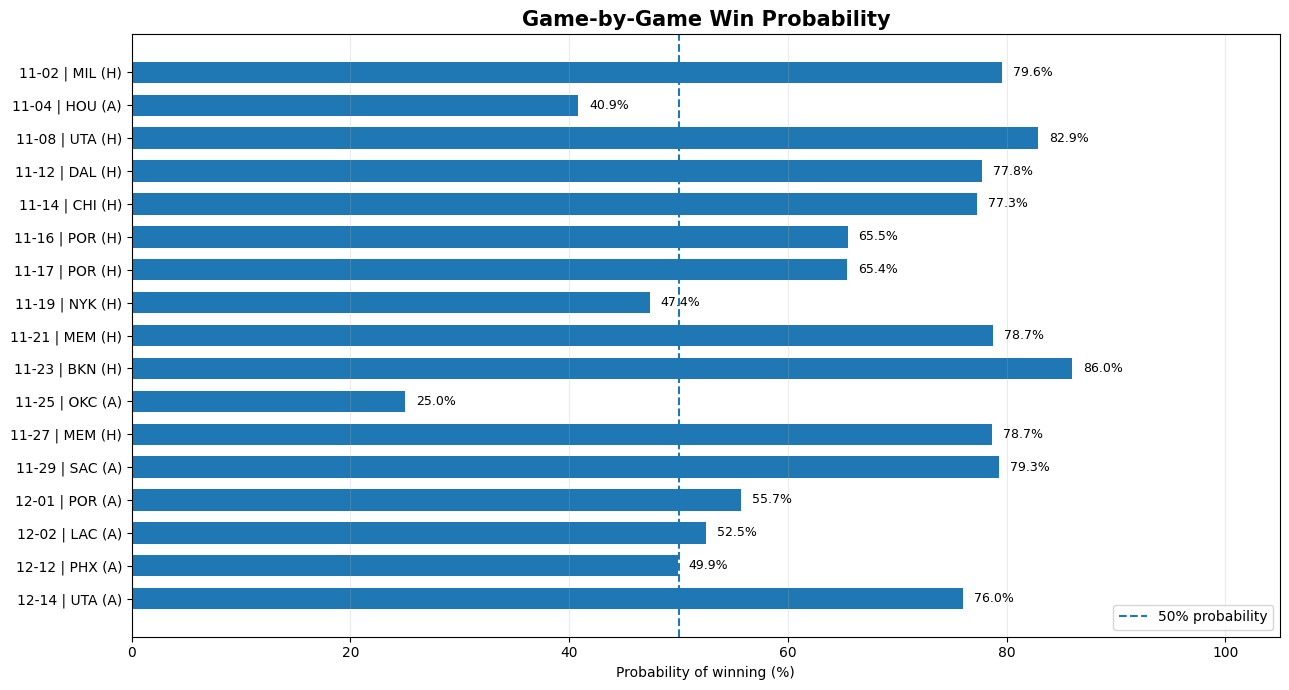

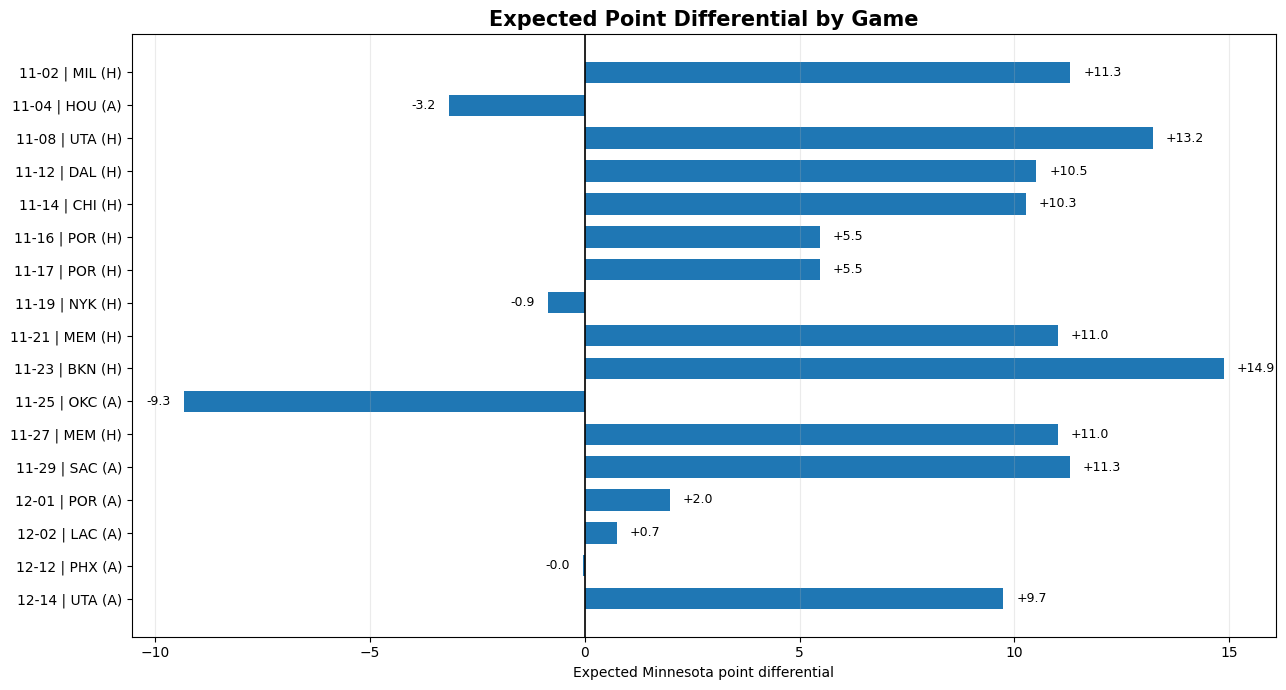

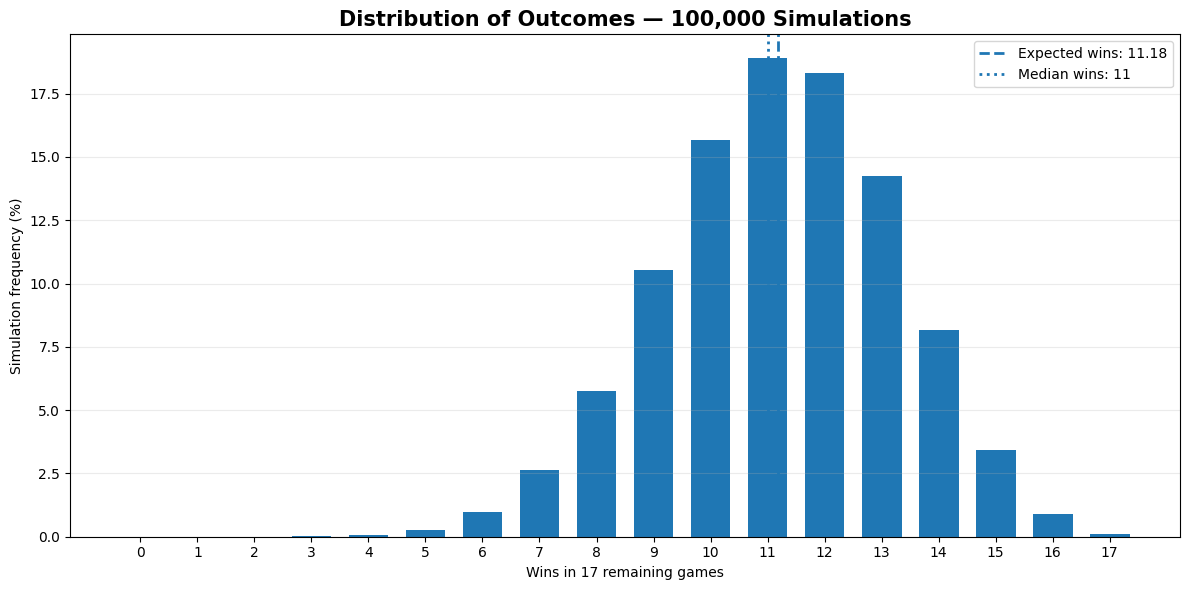


FINAL MODEL CONCLUSION

Most likely outcome       : 11 wins in remaining games
Expected outcome          : 11.18 wins
95% simulation interval   : 7–15 wins

Projected full-stretch record:
11 WINS — 7 LOSSES

Model status: VERSION 1.0 — LOCKED

Important assumption:
Anthony Edwards remains unavailable throughout the forecast period.



In [ ]:
# ============================================================
# FINAL CELL — MINNESOTA TIMBERWOLVES FORECAST DASHBOARD
# ============================================================

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

# ------------------------------------------------------------
# 1. PREPARE DASHBOARD DATA
# ------------------------------------------------------------

dashboard = final_forecast.copy()

dashboard["Game_Label"] = (
    dashboard["Date"].astype(str).str[5:]
    + " | "
    + dashboard["Opponent"]
    + " ("
    + dashboard["Location"].str[0]
    + ")"
)

# ------------------------------------------------------------
# 2. PRINT HEADLINE METRICS
# ------------------------------------------------------------

print("\n" + "=" * 75)
print("MINNESOTA TIMBERWOLVES")
print("WITHOUT ANTHONY EDWARDS — FINAL FORECAST")
print("=" * 75)

print(f"""
PROJECTED RECORD       : 11–7
EXPECTED WINS           : {final_expected_wins:.2f} / 17 remaining games
MEDIAN WINS             : {final_median_wins:.0f}
95% SIMULATION RANGE    : {final_lower:.0f}–{final_upper:.0f} wins
BASELINE TEAM RATING    : {FINAL_BASELINE_RATING:+.2f}
GAME-LEVEL STANDARD DEV : {FINAL_GAME_SD:.2f}
MONTE CARLO SIMULATIONS : {N_SIMULATIONS:,}

COMPLETED GAME:
Minnesota vs San Antonio: LOSS (111–121)

FORECASTED GAMES:
17 remaining games
""")

# ------------------------------------------------------------
# 3. VISUALISATION 1 — GAME-BY-GAME WIN PROBABILITY
# ------------------------------------------------------------

fig, ax = plt.subplots(figsize=(13, 7))

y = np.arange(len(dashboard))

ax.barh(
    y,
    dashboard["Win_Probability"],
    height=0.65
)

ax.axvline(
    50,
    linestyle="--",
    linewidth=1.5,
    label="50% probability"
)

ax.set_yticks(y)
ax.set_yticklabels(dashboard["Game_Label"])

ax.invert_yaxis()
ax.set_xlim(0, 105)

ax.set_xlabel("Probability of winning (%)")
ax.set_title(
    "Game-by-Game Win Probability",
    fontsize=15,
    fontweight="bold"
)

for i, probability in enumerate(
    dashboard["Win_Probability"]
):
    ax.text(
        probability + 1,
        i,
        f"{probability:.1f}%",
        va="center",
        fontsize=9
    )

ax.grid(axis="x", alpha=0.25)
ax.legend(loc="lower right")

plt.tight_layout()
plt.show()


# ------------------------------------------------------------
# 4. VISUALISATION 2 — EXPECTED POINT DIFFERENTIAL
# ------------------------------------------------------------

fig, ax = plt.subplots(figsize=(13, 7))

margins = dashboard["Expected_Margin"]

ax.barh(
    y,
    margins,
    height=0.65
)

ax.axvline(
    0,
    color="black",
    linewidth=1.2
)

ax.set_yticks(y)
ax.set_yticklabels(dashboard["Game_Label"])

ax.invert_yaxis()

ax.set_xlabel("Expected Minnesota point differential")
ax.set_title(
    "Expected Point Differential by Game",
    fontsize=15,
    fontweight="bold"
)

for i, margin in enumerate(margins):

    if margin >= 0:
        ax.text(
            margin + 0.3,
            i,
            f"+{margin:.1f}",
            va="center",
            fontsize=9
        )
    else:
        ax.text(
            margin - 0.3,
            i,
            f"{margin:.1f}",
            va="center",
            ha="right",
            fontsize=9
        )

ax.grid(axis="x", alpha=0.25)

plt.tight_layout()
plt.show()


# ------------------------------------------------------------
# 5. VISUALISATION 3 — MONTE CARLO WIN DISTRIBUTION
# ------------------------------------------------------------

fig, ax = plt.subplots(figsize=(12, 6))

win_counts = np.bincount(
    final_simulated_wins,
    minlength=18
)

win_percentages = (
    win_counts / len(final_simulated_wins)
) * 100

win_values = np.arange(18)

ax.bar(
    win_values,
    win_percentages,
    width=0.7
)

ax.axvline(
    final_expected_wins,
    linestyle="--",
    linewidth=2,
    label=f"Expected wins: {final_expected_wins:.2f}"
)

ax.axvline(
    final_median_wins,
    linestyle=":",
    linewidth=2,
    label=f"Median wins: {final_median_wins:.0f}"
)

ax.set_xticks(range(18))

ax.set_xlabel("Wins in 17 remaining games")
ax.set_ylabel("Simulation frequency (%)")

ax.set_title(
    "Distribution of Outcomes — 100,000 Simulations",
    fontsize=15,
    fontweight="bold"
)

ax.grid(axis="y", alpha=0.25)
ax.legend()

plt.tight_layout()
plt.show()


# ------------------------------------------------------------
# 6. FINAL SUMMARY
# ------------------------------------------------------------

print("\n" + "=" * 75)
print("FINAL MODEL CONCLUSION")
print("=" * 75)

print(f"""
Most likely outcome       : {int(final_median_wins)} wins in remaining games
Expected outcome          : {final_expected_wins:.2f} wins
95% simulation interval   : {final_lower:.0f}–{final_upper:.0f} wins

Projected full-stretch record:
11 WINS — 7 LOSSES

Model status: VERSION 1.0 — LOCKED

Important assumption:
Anthony Edwards remains unavailable throughout the forecast period.
""")